# 1. Introduction

Music recommendation systems help listeners discover tracks based on their musical preferences and the characteristics of songs. Audio features such as danceability, energy, acousticness and tempo can provide useful information about how tracks differ from or resemble one another.

This project investigates whether Spotify track data could be used to identify musical similarities and support the development of a music recommendation system. The analysis will focus on understanding the dataset, assessing data quality and exploring relationships between audio features before considering the development of a recommendation algorithm.

The analysis will address three research questions:

1. Which audio features may be useful for identifying similarities between songs?
2. What relationships exist between Spotify's audio features?
3. How suitable is the dataset for developing a music recommendation system?

The findings will help establish whether the dataset is suitable for further analysis and provide a foundation for future recommendation modelling.

In [2]:
import pandas as pd

df = pd.read_csv(
    "hf://datasets/maharshipandya/spotify-tracks-dataset/dataset.csv"
)

pd.set_option('display.max_columns', None)

## 2. Dataset Overview

The Spotify tracks dataset contains information about individual tracks, including track metadata and audio features. Before cleaning or analysing the data, I will examine its dimensions, column names, data types and initial records to understand its structure.

In [3]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [4]:
df.shape

(114000, 21)

In [5]:
df.columns

Index(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name',
       'popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [7]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


## 3. Data Quality Assessment

Before analysing the relationships between Spotify audio features, I will assess the dataset for missing values, duplicate records and potential inconsistencies. This will help establish whether the data is sufficiently complete and reliable for the planned analysis.

In [8]:
df.isnull().sum()

#Counts the missing values in each column. Helps us confirm if only three columns identified in df.info().

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [9]:
df[df.isnull().any(axis=1)]

#Displays rows containing at least one missing value. Can check whether the three missing entries belong to the same track record.

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [10]:
df.duplicated().sum()

#This counts rows that are exact duplicates of earlier rows across all columns.

np.int64(0)

In [11]:
df['track_id'].duplicated().sum()

#Checks for duplicated track IDs. Repeated IDs are not automatically errors, but they may matter if we later want to recommend unique tracks.

np.int64(24259)

In [12]:
df['Unnamed: 0'].head(10)

0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
Name: Unnamed: 0, dtype: int64

In [13]:
df['Unnamed: 0'].nunique()

#These will help us understand whether the column simply contains a unique row index or something else.

114000

In [14]:
# Find track IDs that appear more than once
repeated_ids = df[df['track_id'].duplicated(keep=False)]

# Display examples, sorted by track ID
repeated_ids.sort_values('track_id').head(10)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,1,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,1,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,2,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,2,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,ska
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,rock
3257,3257,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alternative
2106,2106,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alt-rock
33178,33178,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,5,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,emo
94239,94239,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,5,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,sad
97533,97533,006rHBBNLJMpQs8fRC2GDe,Calcinha Preta;Gusttavo Lima,CP 25 Anos (Ao Vivo em Aracaju),Agora Estou Sofrendo - Ao Vivo,47,260510,False,0.605,0.678,0,-3.257,1,0.0311,0.64200,0.000000,0.1570,0.439,125.059,4,sertanejo


In [15]:
# Count how many different genres each track ID has
df.groupby('track_id')['track_genre'].nunique().value_counts().sort_index()

track_genre
1    73442
2    11424
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64

In [16]:
# Count how many distinct genres each track ID has
genres_per_track = df.groupby('track_id')['track_genre'].nunique()

# Identify track IDs that occur more than once
repeated_track_ids = df['track_id'].value_counts()
repeated_track_ids = repeated_track_ids[repeated_track_ids > 1].index

# Display examples of repeated IDs and their records
df[df['track_id'].isin(repeated_track_ids)].sort_values(
    'track_id'
)[['track_id', 'track_name', 'artists', 'track_genre',
   'popularity', 'danceability', 'energy']].head(20)

,track_id,track_name,artists,track_genre,popularity,danceability,energy
15028,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,chill,0,0.613,0.471
103211,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,soul,0,0.613,0.471
85578,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,punk-rock,38,0.554,0.921
100420,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,ska,38,0.554,0.921
91801,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,rock,86,0.352,0.911
3257,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alternative,86,0.352,0.911
2106,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alt-rock,86,0.352,0.911
33178,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,emo,58,0.808,0.331
94239,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,sad,58,0.808,0.331
97533,006rHBBNLJMpQs8fRC2GDe,Agora Estou Sofrendo - Ao Vivo,Calcinha Preta;Gusttavo Lima,sertanejo,47,0.605,0.678


In [17]:
# Select the numerical audio features
audio_features = [
    'danceability', 'energy', 'key', 'loudness', 'mode',
    'speechiness', 'acousticness', 'instrumentalness',
    'liveness', 'valence', 'tempo', 'time_signature'
]

# Count distinct values per track ID for each audio feature
df.groupby('track_id')[audio_features].nunique().max()

danceability        1
energy              1
key                 1
loudness            1
mode                1
speechiness         1
acousticness        1
instrumentalness    1
liveness            1
valence             1
tempo               1
time_signature      1
dtype: int64

### Initial Data Quality Findings

The dataset contains 114,000 rows and 21 columns. One record has missing values in `artists`, `album_name` and `track_name`, although its track ID, genre and audio features are present.

No exact duplicate rows were identified. However, some track IDs appear multiple times under different genre labels. Inspection of sample records found that repeated records retain consistent values across all 12 numerical audio features examined. This suggests that repeated IDs reflect the dataset's genre categorisation rather than necessarily being errors. The original records will be retained for now, with the handling of repeated tracks considered during preparation for recommendation modelling.

The `Unnamed: 0` column contains 114,000 unique sequential values, suggesting that it is an exported row index rather than a meaningful feature. It will be considered for removal during data preparation.

## 4. Data Cleaning and Preparation

Following the initial data quality assessment, the dataset will be prepared for exploratory data analysis. This stage involves removing unnecessary columns and addressing missing values where appropriate, while preserving useful information about tracks and their genre classifications. The original dataset will be retained so that cleaning decisions can be made without altering the source data.

In [18]:
# Create a cleaned working dataset without the exported row-index column
df_clean = df.drop(columns=['Unnamed: 0'])

# Confirm the exported index column has been removed
'Unnamed: 0' in df_clean.columns

False

### Handling Missing Metadata

The data quality assessment identified one record with missing values in the `artists`, `album_name` and `track_name` columns. However, the record retains its track ID, genre and numerical audio features. As these features may still be useful for exploratory data analysis, the record will be retained rather than removed at this stage. Analyses and recommendation outputs that require complete track metadata may exclude this record where necessary. The missing values will not be replaced with invented information.

## 5. Exploratory Data Analysis

Exploratory data analysis (EDA) will be used to investigate the distribution of Spotify's audio features and identify patterns that may be useful for music recommendation. This stage will examine the characteristics of individual features, relationships between features and differences between musical genres.

The analysis will focus on features such as danceability, energy, acousticness, instrumentalness, valence and tempo. Visualisations and summary statistics will be used to understand the data, identify potential relationships and assess which features may help distinguish between tracks.

The findings will help determine which audio features are worth considering when developing a music recommendation system in future work.

In [19]:
# Select the audio features for analysis
audio_features = [
    'danceability', 'energy', 'acousticness',
    'instrumentalness', 'valence', 'tempo',
    'speechiness', 'liveness', 'loudness'
]

# Calculate summary statistics
df_clean[audio_features].describe()

,danceability,energy,acousticness,instrumentalness,valence,tempo,speechiness,liveness,loudness
count,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,0.566800,0.641383,0.314910,0.156050,0.474068,122.147837,0.084652,0.213553,-8.258960
std,0.173542,0.251529,0.332523,0.309555,0.259261,29.978197,0.105732,0.190378,5.029337
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-49.531000
25%,0.456000,0.472000,0.016900,0.000000,0.260000,99.218750,0.035900,0.098000,-10.013000
50%,0.580000,0.685000,0.169000,0.000042,0.464000,122.017000,0.048900,0.132000,-7.004000
75%,0.695000,0.854000,0.598000,0.049000,0.683000,140.071000,0.084500,0.273000,-5.003000
max,0.985000,1.000000,0.996000,1.000000,0.995000,243.372000,0.965000,1.000000,4.532000


### Summary Statistics

The summary statistics show variation across the selected audio features. Danceability, energy and valence are measured on a scale from 0 to 1, while tempo and loudness use different units. This means that the numerical values of different features should not be compared directly without considering their scales.

Acousticness, instrumentalness, speechiness and liveness have means that exceed their medians, suggesting that higher values may influence their averages. Instrumentalness has a particularly low median, indicating that at least half of the records have very low instrumentalness values.

All nine selected features contain 114,000 observations, with no missing values. However, the minimum tempo of zero and the wide range of loudness values warrant further investigation. Histograms will be used next to examine the distributions and identify any potentially unusual values.

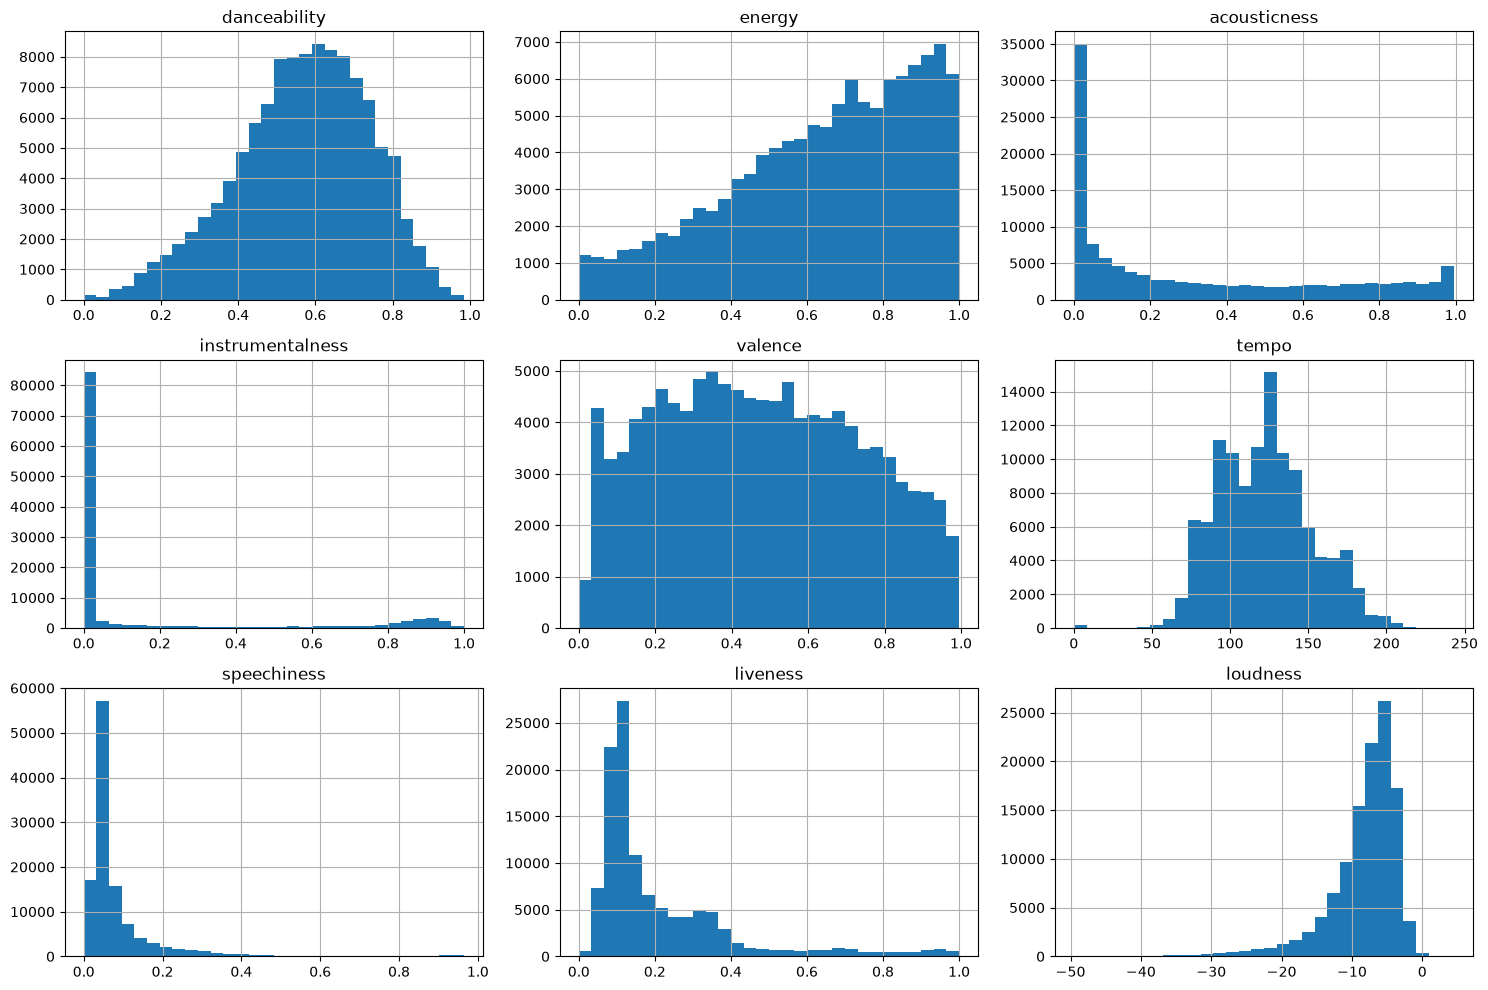

In [20]:
import matplotlib.pyplot as plt

# Plot the distribution of each selected audio feature
df_clean[audio_features].hist(
    figsize=(15, 10),
    bins=30
)

plt.tight_layout()
plt.show()

### Audio Feature Distributions

The histograms reveal considerable variation in the distributions of Spotify's audio features. Danceability is concentrated around the middle of its scale, while energy values tend to be higher. Valence is more widely distributed, indicating variation in the musical mood represented by this feature.

Acousticness, instrumentalness, speechiness and liveness are strongly right-skewed, with most tracks having relatively low values and fewer tracks having high values. In particular, instrumentalness is concentrated very close to zero.

Tempo is mainly concentrated between approximately 80 and 160 BPM, while loudness values are concentrated in a narrower range with a tail towards lower values. The histograms also highlight potentially unusual observations, particularly a tempo value near zero and extreme loudness values.

These distributions suggest that the selected features capture different characteristics of tracks and may contribute useful information to a future recommendation system. However, further analysis is needed to investigate relationships between features and determine how they could be used to identify similar tracks.

In [21]:
# Find tracks with a tempo of zero
df_clean[df_clean['tempo'] == 0][
    ['track_id', 'track_name', 'artists', 'track_genre', 'tempo']
]

,track_id,track_name,artists,track_genre,tempo
4131,59gg6zQhSKGVnkT3hWAY3l,The Departure,Max Richter;Lang Lang,ambient,0.0
4379,4acmzQsAeMJa5sGFSog7fu,The End of Childhood (feat. Jack Liebeck),Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,ambient,0.0
4664,1Kb2DqjHRvOcT5xeWtz3t5,Ferme Les Yeux,Sylvain Chauveau,ambient,0.0
45670,6B9Mgf9smWqxDjA35VD6MK,Campomoro,Little Symphony,guitar,0.0
45720,7i5OoyPXtSrqz9jobJfG1F,Ritornello,Little Symphony,guitar,0.0
...,...,...,...,...,...
101988,5gEKRH0MCSegG8ZISUPaU2,Tin White Noise,Granular,sleep,0.0
101993,6H0kAiSAFB84jX7dgEDWd6,Rain: Natural Recording,Rain Sounds,sleep,0.0
113428,5EYzrykQ95uOmepteDi9KT,Aire de verano,El Ruido Blanco;Soñoliento Juan;Mantra para Do...,world-music,0.0
113688,2EnZf7wbFv7ST4CJ3EvNzT,Ruido Rosa Puro - Una Hora Versión,El Ruido Blanco,world-music,0.0


In [22]:
# Count tracks with a tempo of zero
zero_tempo_count = (df_clean['tempo'] == 0).sum()

# Calculate the percentage of the dataset
zero_tempo_percentage = zero_tempo_count / len(df_clean) * 100

print(f"Tracks with zero tempo: {zero_tempo_count}")
print(f"Percentage of dataset: {zero_tempo_percentage:.2f}%")

Tracks with zero tempo: 157
Percentage of dataset: 0.14%


### Investigation of Zero-Tempo Records

The tempo histogram revealed a small number of records with a tempo of zero. Further investigation identified 157 such records, representing approximately 0.14% of the dataset. The sample includes ambient music, sleep music and sound recordings, suggesting that some tracks may not have a conventional or easily detectable beat.

A tempo value of zero may indicate that a tempo was not detected rather than representing a meaningful tempo measurement. These records will be retained in the cleaned dataset at this stage, as removing them could exclude potentially valid tracks. If tempo is used in future recommendation modelling, these records may require separate treatment to avoid misleading comparisons.

In [23]:
# Calculate correlations between audio features
correlation_matrix = df_clean[audio_features].corr()

correlation_matrix

,danceability,energy,acousticness,instrumentalness,valence,tempo,speechiness,liveness,loudness
danceability,1.000000,0.134325,-0.171533,-0.185606,0.477341,-0.050450,0.108626,-0.131617,0.259077
energy,0.134325,1.000000,-0.733906,-0.181879,0.258934,0.247851,0.142509,0.184796,0.761690
acousticness,-0.171533,-0.733906,1.000000,0.104027,-0.107070,-0.208224,-0.002186,-0.020700,-0.589803
instrumentalness,-0.185606,-0.181879,0.104027,1.000000,-0.324312,-0.050330,-0.089616,-0.079893,-0.433477
valence,0.477341,0.258934,-0.107070,-0.324312,1.000000,0.078273,0.036635,0.019086,0.279848
tempo,-0.050450,0.247851,-0.208224,-0.050330,0.078273,1.000000,0.017273,0.000600,0.212446
speechiness,0.108626,0.142509,-0.002186,-0.089616,0.036635,0.017273,1.000000,0.205219,0.060826
liveness,-0.131617,0.184796,-0.020700,-0.079893,0.019086,0.000600,0.205219,1.000000,0.076899
loudness,0.259077,0.761690,-0.589803,-0.433477,0.279848,0.212446,0.060826,0.076899,1.000000


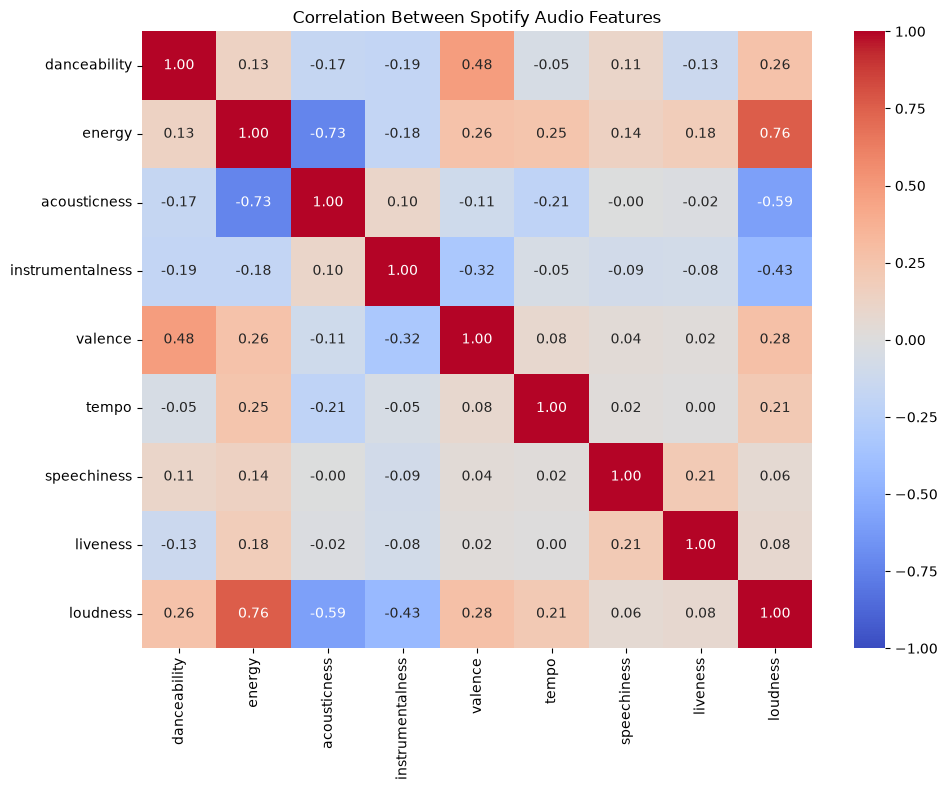

In [24]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Spotify Audio Features')
plt.tight_layout()
plt.show()

### Correlation Analysis

The correlation analysis identified several relationships between Spotify's audio features. The strongest positive correlation was between energy and loudness (0.762), indicating that higher-energy tracks tend to have higher loudness values. Energy and acousticness had a strong negative correlation (-0.734), suggesting that higher-energy tracks tend to have lower acousticness scores.

A moderate positive correlation was observed between danceability and valence (0.477), while acousticness and loudness (-0.590) and instrumentalness and loudness (-0.433) showed negative relationships. In contrast, several feature pairs, including tempo and liveness, had correlations close to zero.

These results suggest that some audio features capture related characteristics, while others provide different information about tracks. This is relevant to recommendation modelling because combining multiple features may help identify similar songs. However, strongly correlated features may provide overlapping information, and their usefulness should be evaluated in the context of the recommendation method. Correlation indicates association rather than causation.

In [25]:
# Count records for each genre
df_clean['track_genre'].value_counts()

track_genre
acoustic             1000
punk-rock            1000
progressive-house    1000
power-pop            1000
pop                  1000
                     ... 
folk                 1000
emo                  1000
electronic           1000
electro              1000
world-music          1000
Name: count, Length: 114, dtype: int64

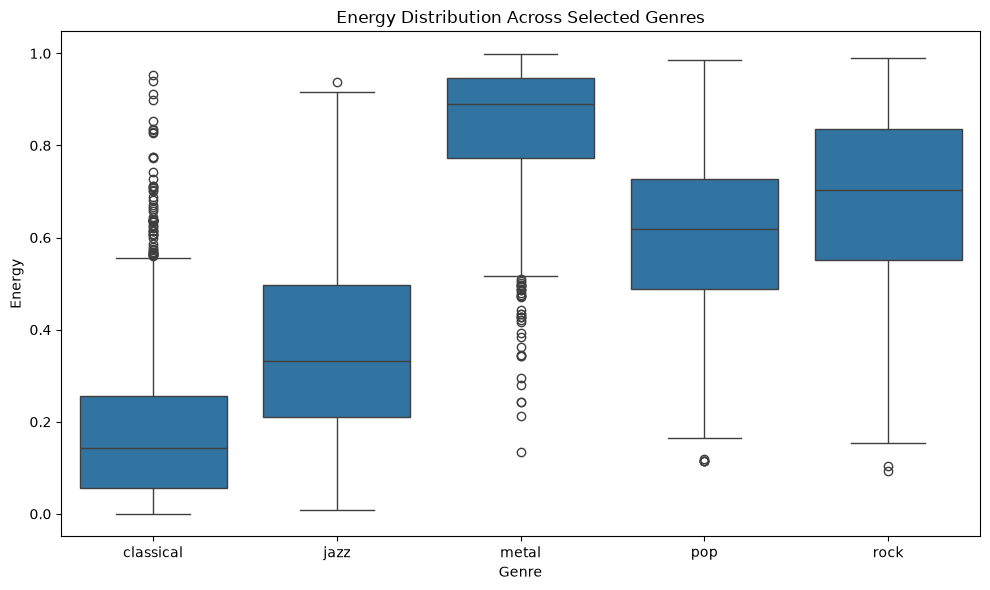

In [26]:
# Select five genres for comparison
selected_genres = [
    'pop', 'rock', 'classical', 'jazz', 'metal'
]

genre_data = df_clean[
    df_clean['track_genre'].isin(selected_genres)
]

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=genre_data,
    x='track_genre',
    y='energy'
)

plt.title('Energy Distribution Across Selected Genres')
plt.xlabel('Genre')
plt.ylabel('Energy')
plt.tight_layout()
plt.show()

### Energy Distribution Across Genres

The boxplot shows clear differences in the energy distributions of the five selected genres. Classical tracks have the lowest median energy, at approximately 0.14, while metal tracks have the highest, at approximately 0.89. Jazz has a median of around 0.33, compared with approximately 0.62 for pop and 0.70 for rock.

The distributions also reveal variation within each genre. Pop and rock have relatively wide distributions, while classical and metal contain several observations outside their main ranges. These outliers may represent genuine differences between individual tracks and should not automatically be treated as errors.

The results suggest that energy could help distinguish some musical styles. However, the overlap between genres indicates that energy alone is unlikely to be sufficient for identifying similar tracks. Combining multiple audio features may provide a more useful basis for future recommendation modelling.

In [27]:
# Calculate summary statistics for acousticness by genre
acousticness_by_genre = (
    df_clean.groupby('track_genre')['acousticness']
    .agg(['mean', 'median', 'std', 'count'])
    .sort_values('median')
)

acousticness_by_genre

,mean,median,std,count
track_genre,,,,
grindcore,0.008698,0.000015,0.048092,1000
black-metal,0.027056,0.000044,0.128681,1000
death-metal,0.006696,0.000131,0.041438,1000
metalcore,0.010286,0.000291,0.048160,1000
heavy-metal,0.014968,0.000431,0.053239,1000
...,...,...,...,...
ambient,0.776790,0.920500,0.301232,1000
romance,0.869495,0.950000,0.191416,1000
new-age,0.824022,0.950000,0.267752,1000


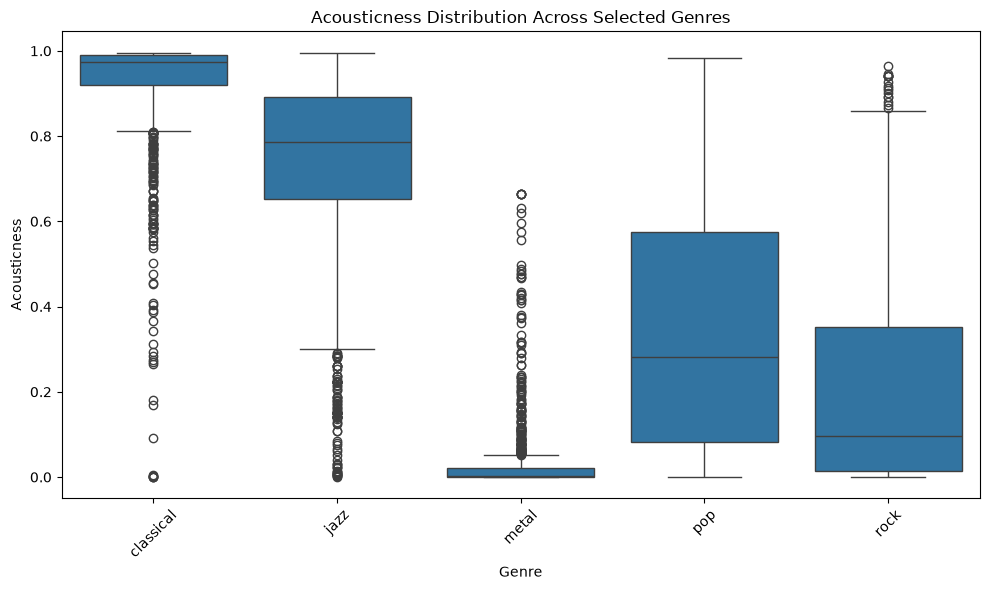

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

selected_genres = ['pop', 'rock', 'classical', 'jazz', 'metal']

acousticness_data = df_clean[
    df_clean['track_genre'].isin(selected_genres)
]

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=acousticness_data,
    x='track_genre',
    y='acousticness'
)

plt.title('Acousticness Distribution Across Selected Genres')
plt.xlabel('Genre')
plt.ylabel('Acousticness')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Relevance to the Energy Distribution Plot:
When cross-referenced with the previously analyzed `energy` distribution plot, a clear **inverse relationship** emerges between these two features across genres:
* **Classical and Metal act as polar opposites:** Classical features maximum acousticness and minimum energy, while Metal features maximum energy and minimum acousticness.
* **Jazz vs. Rock/Pop:** Jazz mirrors Rock and Pop in reverse structural behavior; Jazz keeps a high acoustic/lower energy profile, whereas Rock and Pop lean significantly higher in energy while giving up acoustic dominance.

#### Implications for the Recommendation System:
These distinct, genre-specific profiles directly address our first two research questions. They confirm that `acousticness` and `energy` are highly contrasting features that capture strong variance between different musical styles. Because these distributions map cleanly to recognizable genre differences, both features will be **highly useful inputs for identifying musical similarities** and distinguishing tracks in a recommendation algorithm.


In [29]:
# Create a list of genres for each unique track
aggregation_rules = {
    column: 'first'
    for column in df_clean.columns
    if column not in ['track_id', 'track_genre']
}

aggregation_rules['track_genre'] = (
    lambda genres: sorted(genres.dropna().unique().tolist())
)

df_tracks = (
    df_clean
    .groupby('track_id', as_index=False)
    .agg(aggregation_rules)
)

df_tracks.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0000vdREvCVMxbQTkS888c,Rill,Lolly,Lolly,44,160725,True,0.910,0.374,8,-9.844,0,0.1990,0.075700,0.00301,0.1540,0.432,104.042,4,[german]
1,000CC8EParg64OmTxVnZ0p,Glee Cast,Glee Love Songs,It's All Coming Back To Me Now (Glee Cast Vers...,47,322933,False,0.269,0.516,0,-7.361,1,0.0366,0.406000,0.00000,0.1170,0.341,178.174,4,[club]
2,000Iz0K615UepwSJ5z2RE5,Paul Kalkbrenner;Pig&Dan,X,Böxig Leise - Pig & Dan Remix,22,515360,False,0.686,0.560,5,-13.264,0,0.0462,0.001140,0.18100,0.1110,0.108,119.997,4,[minimal-techno]
3,000RDCYioLteXcutOjeweY,Jordan Sandhu,Teeje Week,Teeje Week,62,190203,False,0.679,0.770,0,-3.537,1,0.1900,0.058300,0.00000,0.0825,0.839,161.721,4,[hip-hop]
4,000qpdoc97IMTBvF8gwcpy,Paul Kalkbrenner,Zeit,Tief,19,331240,False,0.519,0.431,6,-13.606,0,0.0291,0.000964,0.72000,0.0916,0.234,129.971,4,[minimal-techno]


In [30]:

# Compare the original and consolidated dataset sizes
print("Original rows:", len(df_clean))
print("Consolidated rows:", len(df_tracks))
print("Unique track IDs:", df_tracks['track_id'].nunique())

# Confirm that every track ID appears exactly once
print("All track IDs unique:", df_tracks['track_id'].is_unique)

# Check how many genres are associated with each track
print(df_tracks['track_genre'].str.len().value_counts().sort_index())


Original rows: 114000
Consolidated rows: 89741
Unique track IDs: 89741
All track IDs unique: True
track_genre
1    73442
2    11424
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64


In [31]:
print(df_tracks.shape)
print(df_tracks.columns.tolist())
print(df_tracks['track_id'].isna().sum())

(89741, 20)
['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']
0


### Consolidating Duplicate Track IDs

The original dataset contained 114,000 rows, which were consolidated into 89,741 unique tracks by grouping records by `track_id`. Multiple genre labels were combined into lists, while the first value was retained for other columns. Previous checks confirmed that repeated track IDs had consistent audio features.

Validation confirmed that every `track_id` appears exactly once. The consolidated dataset, `df_tracks`, is now better suited for preparing audio features for future recommendation modelling.

### Preparing Audio Features for Recommendation Modelling.

In [32]:
audio_features = [
    'danceability',
    'energy',
    'acousticness',
    'instrumentalness',
    'valence',
    'tempo',
    'speechiness',
    'liveness',
    'loudness'
]

In [33]:
X = df_tracks[audio_features].copy()

X.head()

,danceability,energy,acousticness,instrumentalness,valence,tempo,speechiness,liveness,loudness
0,0.910,0.374,0.075700,0.00301,0.432,104.042,0.1990,0.1540,-9.844
1,0.269,0.516,0.406000,0.00000,0.341,178.174,0.0366,0.1170,-7.361
2,0.686,0.560,0.001140,0.18100,0.108,119.997,0.0462,0.1110,-13.264
3,0.679,0.770,0.058300,0.00000,0.839,161.721,0.1900,0.0825,-3.537
4,0.519,0.431,0.000964,0.72000,0.234,129.971,0.0291,0.0916,-13.606


In [34]:
print(X.isnull().sum())
print(X.describe())

danceability        0
energy              0
acousticness        0
instrumentalness    0
valence             0
tempo               0
speechiness         0
liveness            0
loudness            0
dtype: int64
       danceability        energy  acousticness  instrumentalness  \
count  89741.000000  89741.000000  89741.000000      89741.000000   
mean       0.562166      0.634458      0.328289          0.173413   
std        0.176691      0.256605      0.338321          0.323848   
min        0.000000      0.000000      0.000000          0.000000   
25%        0.450000      0.457000      0.017100          0.000000   
50%        0.576000      0.676000      0.188000          0.000058   
75%        0.692000      0.853000      0.625000          0.097600   
max        0.985000      1.000000      0.996000          1.000000   

            valence         tempo   speechiness      liveness      loudness  
count  89741.000000  89741.000000  89741.000000  89741.000000  89741.000000  
mean       

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled[:5]

array([[ 1.9686116 , -1.01502053, -0.74660022, -0.5261865 , -0.14257432,
        -0.59820362,  0.98482927, -0.32311399, -0.25758991],
       [-1.65920757, -0.46163775,  0.22969745, -0.53548104, -0.48876346,
         1.86323356, -0.44883143, -0.51297121,  0.21794754],
       [ 0.70085576, -0.29016703, -0.96698397,  0.0234263 , -1.3751598 ,
        -0.06844278, -0.36408302, -0.54375887, -0.91257907],
       [ 0.66123839,  0.52821595, -0.79803098, -0.53548104,  1.40576608,
         1.31693741,  0.90537763, -0.69000024,  0.95030969],
       [-0.24430149, -0.79288801, -0.96750419,  1.68779676, -0.89582101,
         0.2627283 , -0.51504113, -0.64330563, -0.97807799]])

## Conclusion

This project explored and prepared Spotify track data to investigate how audio features can support music recommendation algorithms. The dataset was cleaned by removing an unnecessary index column, investigating missing metadata and consolidating repeated track IDs into 89,741 unique tracks while preserving their genre associations.

Exploratory data analysis examined the distributions and correlations of audio features, alongside comparisons of energy and acousticness across genres. These analyses helped identify differences in musical characteristics and highlighted potentially useful features for measuring track similarity.

Nine numerical audio features were selected for future recommendation modelling. Checks confirmed that the selected feature matrix contained no missing values, and the features were standardised using `StandardScaler` to make their scales more comparable.

Overall, this project established a foundation for a future content-based music recommendation system. However, further work is required to calculate track similarities, generate recommendations and evaluate their quality. Future development could also investigate how genre information and user preferences could improve recommendation relevance.

## Feature Engineering and Preparation for Machine Learning

Having completed the initial exploratory data analysis and data cleaning, the next stage is to prepare the dataset for machine learning.

The objective of this stage is to prepare the Spotify audio features for use in a K-Means clustering algorithm. This will allow us to identify groups of tracks with similar musical characteristics.

The following steps will be undertaken:

1. **Feature selection:** Identify the relevant numerical audio features to use for clustering.
2. **Data validation:** Check the selected features for missing values and examine their statistical distributions.
3. **Feature scaling:** Standardise the selected features to ensure that differences in measurement scales do not disproportionately influence clustering.
4. **Data splitting:** Divide the dataset into training and testing sets to support model development and evaluation.

The selected features will initially include danceability, energy, acousticness, instrumentalness, valence, tempo, speechiness, liveness and loudness.

These features will provide the foundation for developing and evaluating the K-Means clustering model.

In [36]:
#establish selected features are present, numerical and free from missing values
features = [
    'danceability',
    'energy',
    'acousticness',
    'instrumentalness',
    'valence',
    'tempo',
    'speechiness',
    'liveness',
    'loudness'
]

X = df_clean[features]

print(X.head())
print(X.describe())
print(X.isnull().sum())

   danceability  energy  acousticness  instrumentalness  valence    tempo  \
0         0.676  0.4610        0.0322          0.000001    0.715   87.917   
1         0.420  0.1660        0.9240          0.000006    0.267   77.489   
2         0.438  0.3590        0.2100          0.000000    0.120   76.332   
3         0.266  0.0596        0.9050          0.000071    0.143  181.740   
4         0.618  0.4430        0.4690          0.000000    0.167  119.949   

   speechiness  liveness  loudness  
0       0.1430    0.3580    -6.746  
1       0.0763    0.1010   -17.235  
2       0.0557    0.1170    -9.734  
3       0.0363    0.1320   -18.515  
4       0.0526    0.0829    -9.681  
        danceability         energy   acousticness  instrumentalness  \
count  114000.000000  114000.000000  114000.000000     114000.000000   
mean        0.566800       0.641383       0.314910          0.156050   
std         0.173542       0.251529       0.332523          0.309555   
min         0.000000       

In [37]:
#Tempo conisderably larger scale, Loudness uses negative values, matters as K-Means uses Euclidean distance to measure observation similarity.
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

print("Unique track IDs:", df_clean['track_id'].nunique())

print("Duplicate track IDs:",
      df_clean['track_id'].duplicated().sum())

Original dataset: (114000, 21)
Cleaned dataset: (114000, 20)
Unique track IDs: 89741
Duplicate track IDs: 24259


In [38]:
# Duplicate track entries belonging to different genres need to be consolidated, else our K-Means clustering would be affected.
# Below takes genre values for each track, removes duplicated and stores remaining genres in a list.  
df_consolidated = df_clean.groupby('track_id').agg({
    'artists': 'first',
    'album_name': 'first',
    'track_name': 'first',
    'popularity': 'first',
    'duration_ms': 'first',
    'explicit': 'first',
    'danceability': 'first',
    'energy': 'first',
    'key': 'first',
    'loudness': 'first',
    'mode': 'first',
    'speechiness': 'first',
    'acousticness': 'first',
    'instrumentalness': 'first',
    'liveness': 'first',
    'valence': 'first',
    'tempo': 'first',
    'time_signature': 'first',
    'track_genre': lambda x: list(x.unique())
}).reset_index()

In [39]:
print(df_consolidated.shape)

print("Unique track IDs:",
      df_consolidated['track_id'].nunique())

print("Duplicate track IDs:",
      df_consolidated['track_id'].duplicated().sum())

(89741, 20)
Unique track IDs: 89741
Duplicate track IDs: 0


In [40]:
X = df_consolidated[features]

print(X.describe())
print(X.isnull().sum())

       danceability        energy  acousticness  instrumentalness  \
count  89741.000000  89741.000000  89741.000000      89741.000000   
mean       0.562166      0.634458      0.328289          0.173413   
std        0.176691      0.256605      0.338321          0.323848   
min        0.000000      0.000000      0.000000          0.000000   
25%        0.450000      0.457000      0.017100          0.000000   
50%        0.576000      0.676000      0.188000          0.000058   
75%        0.692000      0.853000      0.625000          0.097600   
max        0.985000      1.000000      0.996000          1.000000   

            valence         tempo   speechiness      liveness      loudness  
count  89741.000000  89741.000000  89741.000000  89741.000000  89741.000000  
mean       0.469477    122.058316      0.087442      0.216970     -8.499004  
std        0.262864     30.117532      0.113277      0.194884      5.221490  
min        0.000000      0.000000      0.000000      0.000000    -

### Investigating Audio Feature Distributions

Before applying feature scaling, it is important to understand the distributions of the selected audio features.

Histograms will be used to visualise the distribution of each feature and identify potential skewness, unusual values and differences in their numerical ranges.

This investigation will help determine whether any additional transformations or preprocessing steps are necessary before implementing the K-Means clustering algorithm.

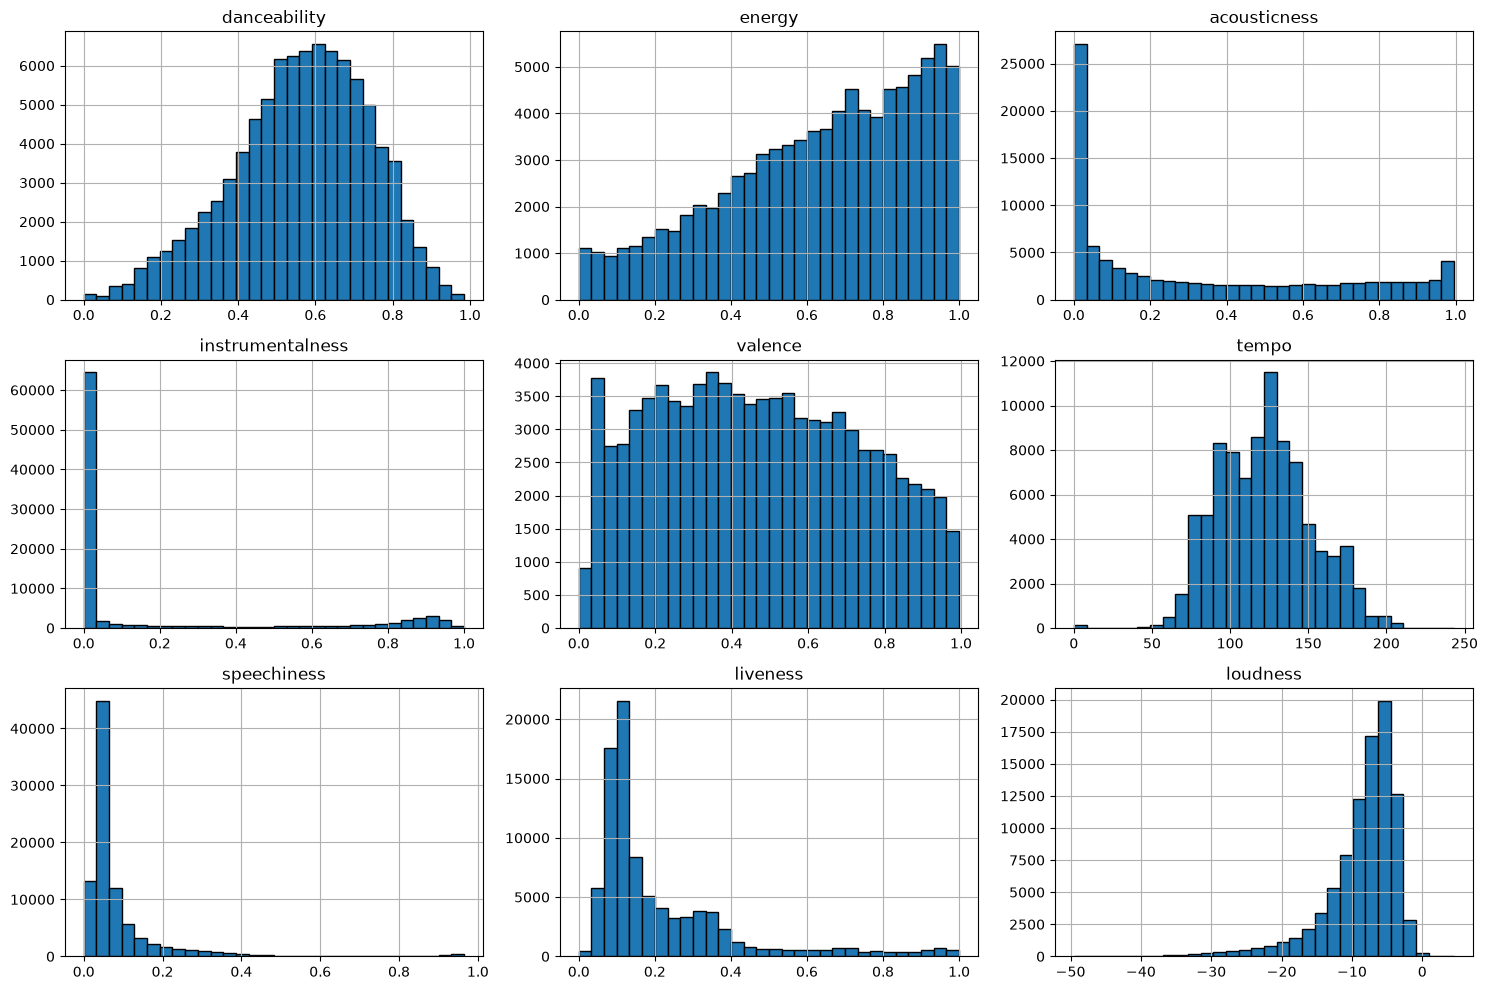

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

X.hist(
    figsize=(15, 10),
    bins=30,
    edgecolor='black'
)

plt.tight_layout()
plt.show()

### Investigating Zero Values and Potential Outliers

The initial visualisation identified several features with highly skewed distributions and potential extreme values.

Before applying feature scaling, it is important to investigate these observations further.

In particular, tempo values of zero and unusually low loudness values will be examined to determine whether they represent legitimate musical characteristics or potentially problematic observations.

This will help inform decisions about whether additional preprocessing is necessary before applying K-Means clustering.

In [42]:
# Count zero values and calculate their percentage
diagnostics = pd.DataFrame({
    'Zero Count': (X == 0).sum(),
    'Zero Percentage': (X == 0).mean() * 100,
    'Minimum': X.min(),
    '1st Percentile': X.quantile(0.01),
    '99th Percentile': X.quantile(0.99),
    'Maximum': X.max()
})

print(diagnostics.round(3))

                  Zero Count  Zero Percentage  Minimum  1st Percentile  \
danceability             157            0.175    0.000           0.123   
energy                     1            0.001    0.000           0.027   
acousticness              39            0.043    0.000           0.000   
instrumentalness       29924           33.345    0.000           0.000   
valence                  176            0.196    0.000           0.033   
tempo                    157            0.175    0.000          65.165   
speechiness              157            0.175    0.000           0.026   
liveness                   2            0.002    0.000           0.041   
loudness                   0            0.000  -49.531         -28.542   

                  99th Percentile  Maximum  
danceability                0.904    0.985  
energy                      0.993    1.000  
acousticness                0.992    0.996  
instrumentalness            0.958    1.000  
valence                     0.965 

In [43]:
tempo_zero = df_consolidated[
    df_consolidated['tempo'] == 0
]

print("Tracks with zero tempo:", len(tempo_zero))

print(
    tempo_zero[
        ['track_name', 'artists', 'tempo', 'duration_ms']
    ].head(10)
)

Tracks with zero tempo: 157
                                     track_name  \
239                            Static Rainstorm   
833                     Fine Noise for Children   
1024   Pure Brown Noise - Loopable with no fade   
1427    Air Conditioner - Loopable With No Fade   
3447       Pouring Rain - Loopable with no fade   
4143         Pure Brown Noise with Pouring Rain   
5048     Pure Brown Noise - Loopable Background   
6201               Healing Noises for Insomniac   
6212                            Continuous Rain   
6853  Clean White Noise - Loopable with No Fade   

                                                artists  tempo  duration_ms  
239   Binaural Beats Brain Waves Isochronic Tones Br...    0.0        99030  
833                     Water Sound Natural White Noise    0.0        63000  
1024  Deep Sleep;Sleep Baby Sleep;Lullabies for Deep...    0.0        71397  
1427       White Noise Sleep Sounds;Sleep Sound Library    0.0        77482  
3447  Meditation Spa

In [44]:
# Several features have 157 zero values - to be checked before handling
# Identify tracks with zero tempo
tempo_zero = df_consolidated[df_consolidated['tempo'] == 0]

# Check how many also have zero values in other features
zero_comparison = (tempo_zero[features] == 0).sum()

print(zero_comparison)

danceability        157
energy                1
acousticness         18
instrumentalness      6
valence             157
tempo               157
speechiness         157
liveness              2
loudness              0
dtype: int64


In [45]:
# Loudness results are also worth examing
# Display the 10 quietest tracks
quietest_tracks = df_consolidated.nsmallest(10, 'loudness')

print(
    quietest_tracks[
        ['track_name', 'artists', 'loudness', 'duration_ms']
    ]
)

                                         track_name  \
68093  Soothing White Noise - Loopable With No Fade   
8399            White Noise - Loopable With No Fade   
59500                Ceiling Fan Sound on Low Power   
74719       Cricket Sound 4 - Loopable With No Fade   
50348       Chaconne in sol maggiore : Variazione 9   
11462                  Nap in the Afternoon Box Fan   
63195                                Loopable Woods   
21974           Sleep Sound For Babies - Underwater   
57041                                  Wake with me   
27840     Clean White Noise - Loopable Without Fade   

                                                 artists  loudness  \
68093                           White Noise Sleep Sounds   -49.531   
8399                            White Noise Sleep Sounds   -49.307   
59500                                    Atmosphere Asmr   -46.591   
74719  White Noise for Babies;Crickets;Baby Sleep Sounds   -46.251   
50348                                       

### Investigating Zero Values and Potential Outliers

Further investigation identified 157 tracks with a tempo value of zero. These tracks also had zero values for danceability, valence and speechiness. Inspection of the track names and artists revealed that many were ambient recordings, including white noise, rain sounds and nature recordings. This suggests that these values may represent non-rhythmic audio rather than missing data.

The loudness distribution also contained unusually low values, with the minimum reaching -49.531 dB. Inspection of the ten quietest tracks showed that most were ambient recordings or nature sounds, although some musical recordings were also present.

Based on these findings, the decision was made to retain all observations and selected audio features. Removing these tracks could exclude legitimate examples of music and ambient audio that may be useful for recommendations.

The effect of extreme values will be considered when comparing feature-scaling methods during model development.

### Feature Scaling

Before applying K-Means clustering, the selected audio features need to be scaled.

K-Means uses distance calculations to determine how similar observations are. Since the selected features have different numerical ranges, features such as tempo and loudness could disproportionately influence the clustering results.

To address this, StandardScaler will initially be used to standardise the features. This transforms each feature so that it has a mean of approximately zero and a standard deviation of approximately one.

This allows the clustering algorithm to consider differences across all selected audio features on a more comparable scale.

In [46]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(89741, 9)


In [47]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

print(X_scaled_df.describe().round(3))

       danceability     energy  acousticness  instrumentalness    valence  \
count     89741.000  89741.000     89741.000         89741.000  89741.000   
mean         -0.000      0.000         0.000            -0.000      0.000   
std           1.000      1.000         1.000             1.000      1.000   
min          -3.182     -2.473        -0.970            -0.535     -1.786   
25%          -0.635     -0.692        -0.920            -0.535     -0.839   
50%           0.078      0.162        -0.415            -0.535     -0.047   
75%           0.735      0.852         0.877            -0.234      0.808   
max           2.393      1.425         1.974             2.552      1.999   

           tempo  speechiness   liveness   loudness  
count  89741.000    89741.000  89741.000  89741.000  
mean      -0.000        0.000     -0.000      0.000  
std        1.000        1.000      1.000      1.000  
min       -4.053       -0.772     -1.113     -7.858  
25%       -0.757       -0.454     -0

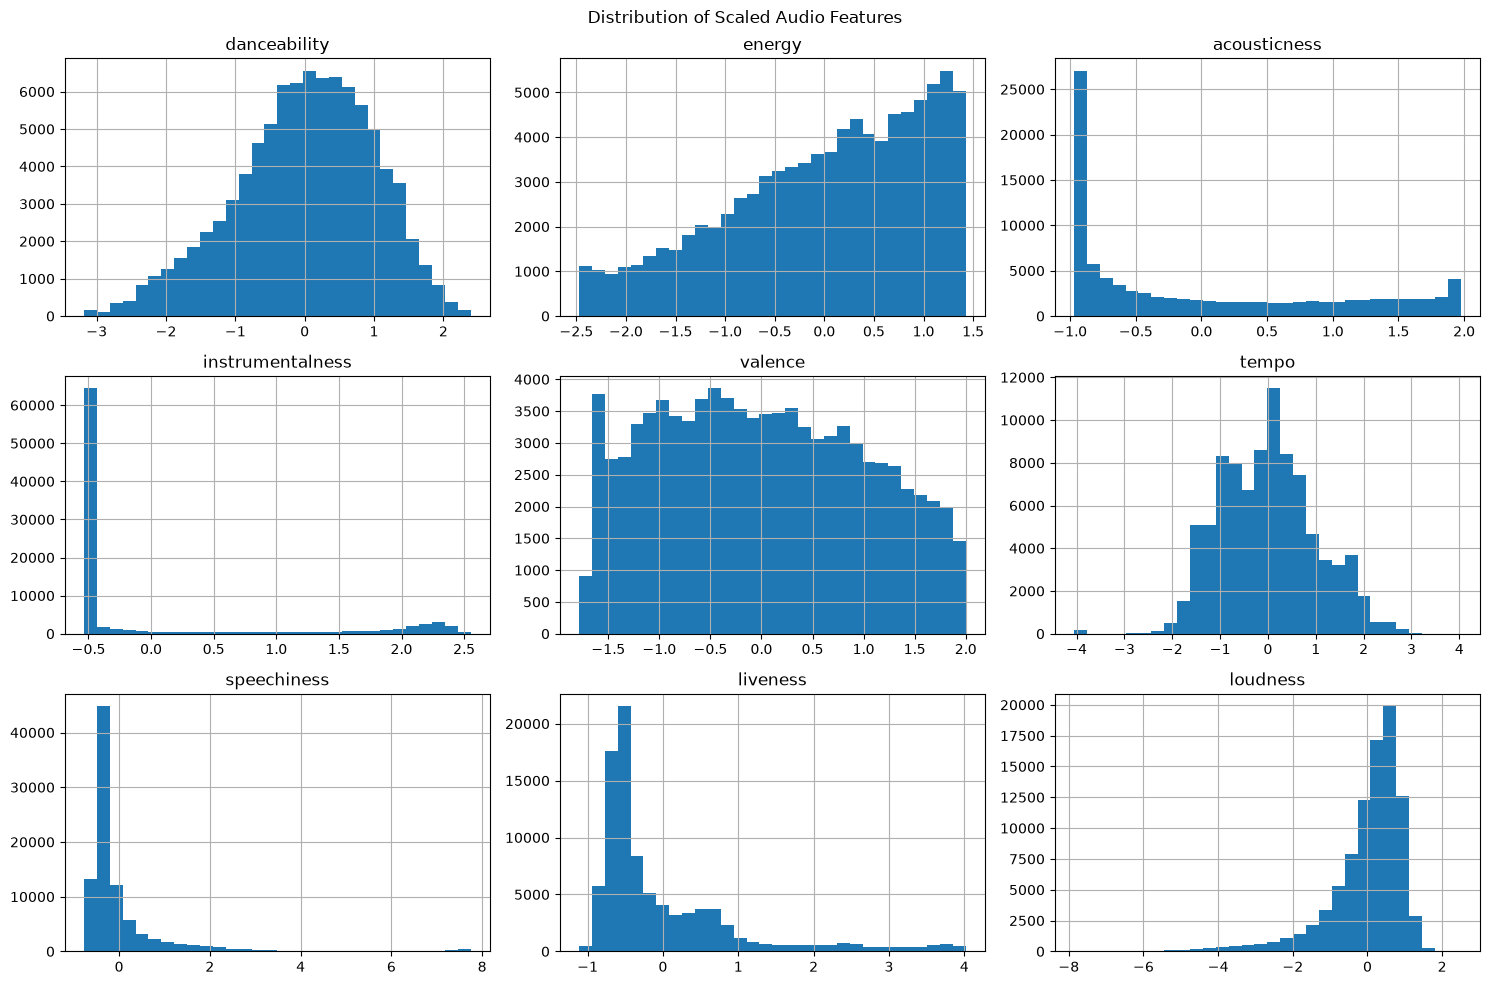

In [48]:
import matplotlib.pyplot as plt

X_scaled_df.hist(
    figsize=(15, 10),
    bins=30
)

plt.suptitle('Distribution of Scaled Audio Features')
plt.tight_layout()
plt.show()

In [49]:
# RobustScaler uses the median to centre each feature and the interquartile range to scale - less sensitive to outliers

from sklearn.preprocessing import RobustScaler

robust_scaler = RobustScaler()

X_robust = robust_scaler.fit_transform(X)

X_robust_df = pd.DataFrame(
    X_robust,
    columns=features
)

print(X_robust_df.describe().round(3))

       danceability     energy  acousticness  instrumentalness    valence  \
count     89741.000  89741.000     89741.000         89741.000  89741.000   
mean         -0.057     -0.105         0.231             1.776      0.029   
std           0.730      0.648         0.557             3.318      0.607   
min          -2.380     -1.707        -0.309            -0.001     -1.055   
25%          -0.521     -0.553        -0.281            -0.001     -0.480   
50%           0.000      0.000         0.000             0.000      0.000   
75%           0.479      0.447         0.719             0.999      0.520   
max           1.690      0.818         1.329            10.245      1.242   

           tempo  speechiness   liveness   loudness  
count  89741.000    89741.000  89741.000  89741.000  
mean       0.001        0.772      0.470     -0.252  
std        0.738        2.270      1.078      1.001  
min       -2.990       -0.980     -0.730     -8.122  
25%       -0.557       -0.259     -0

### Comparing Feature Scaling Methods

Two feature scaling methods were investigated: StandardScaler and RobustScaler.

StandardScaler transforms features using their mean and standard deviation, whereas RobustScaler uses the median and interquartile range (IQR). Consequently, RobustScaler is less sensitive to extreme observations when calculating the scaling parameters.

Both methods successfully transformed the nine selected audio features. StandardScaler produced features with means close to zero and standard deviations of one. RobustScaler produced features with medians of zero and interquartile ranges of one.

However, neither method removes extreme values. Some features, particularly speechiness and instrumentalness, still contain observations that are considerably higher than the majority of the dataset.

Both scaling methods will be retained for comparison during model development. Their impact on K-Means clustering will be evaluated before selecting the final approach.

### Splitting the Dataset

Before developing the clustering model, the dataset will be divided into training and test sets.

An 80/20 split will be used, with 80% of observations allocated to training and 20% reserved for testing.

Although K-Means is an unsupervised learning algorithm and does not require labelled training data, separating the observations allows the model to be developed using one portion of the dataset and evaluated on previously unseen observations.

A fixed random state will be used to ensure that the split can be reproduced.

In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

In [51]:
standard_scaler = StandardScaler()

X_train_scaled = standard_scaler.fit_transform(X_train)

X_test_scaled = standard_scaler.transform(X_test)

In [52]:
robust_scaler = RobustScaler()

X_train_robust = robust_scaler.fit_transform(X_train)

X_test_robust = robust_scaler.transform(X_test)

In [53]:
print("StandardScaler:")
print("Training:", X_train_scaled.shape)
print("Testing:", X_test_scaled.shape)

print("\nRobustScaler:")
print("Training:", X_train_robust.shape)
print("Testing:", X_test_robust.shape)

StandardScaler:
Training: (71792, 9)
Testing: (17949, 9)

RobustScaler:
Training: (71792, 9)
Testing: (17949, 9)


## Model Development: K-Means Clustering

With the audio features cleaned, selected and scaled, the next stage is to develop an unsupervised machine learning model using K-Means clustering.

K-Means aims to divide observations into a specified number of clusters based on similarities in their feature values.

The initial model will be used as a baseline. Different numbers of clusters will then be investigated to identify a suitable grouping of tracks.

Model performance will be evaluated using clustering metrics, including the inertia (within-cluster sum of squares) and silhouette score.

### Developing the Initial K-Means Model

K-Means clustering will be used to identify groups of Spotify tracks with similar audio characteristics.

The algorithm requires the number of clusters to be specified in advance. An initial model will therefore be developed using five clusters as a baseline.

The model will initially be trained using the StandardScaler-transformed training data. Different cluster counts and scaling methods will subsequently be investigated to identify a suitable configuration.

In [54]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans.fit(X_train_scaled)

#n_init=10	Runs the algorithm ten times with different initialisations and retains the best result

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 9)","[[-0.

In [55]:
train_labels = kmeans.labels_

print(train_labels[:20])

[3 3 4 4 3 3 3 3 4 4 3 4 3 0 4 2 4 3 0 4]


In [56]:
import pandas as pd

cluster_sizes = pd.Series(train_labels).value_counts().sort_index()

print(cluster_sizes)

0    16583
1      895
2     5864
3    21516
4    26934
Name: count, dtype: int64


In [57]:
print((cluster_sizes / len(train_labels) * 100).round(2))

0    23.10
1     1.25
2     8.17
3    29.97
4    37.52
Name: count, dtype: float64


### Initial K-Means Results

The initial K-Means model was trained using five clusters and the StandardScaler-transformed training dataset.

The model successfully assigned all 71,792 training observations to one of five clusters.

The resulting cluster distribution was uneven. Cluster 4 contained the largest proportion of tracks (37.52%), while cluster 1 contained the smallest proportion (1.25%).

Uneven cluster sizes are not necessarily an indication of poor clustering, as the algorithm groups observations according to their feature similarities rather than attempting to create equally sized groups.

Further evaluation is required to determine whether five clusters provide a meaningful representation of the dataset.

In [58]:
inertia_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_train_scaled)

    inertia_values.append(kmeans.inertia_)

print(inertia_values)

[505712.487166014, 448900.7351359409, 403967.4284596061, 364114.59799794725, 331352.2879207248, 301087.4275036947, 284577.7799038029, 269787.818209692, 258787.29299675592]


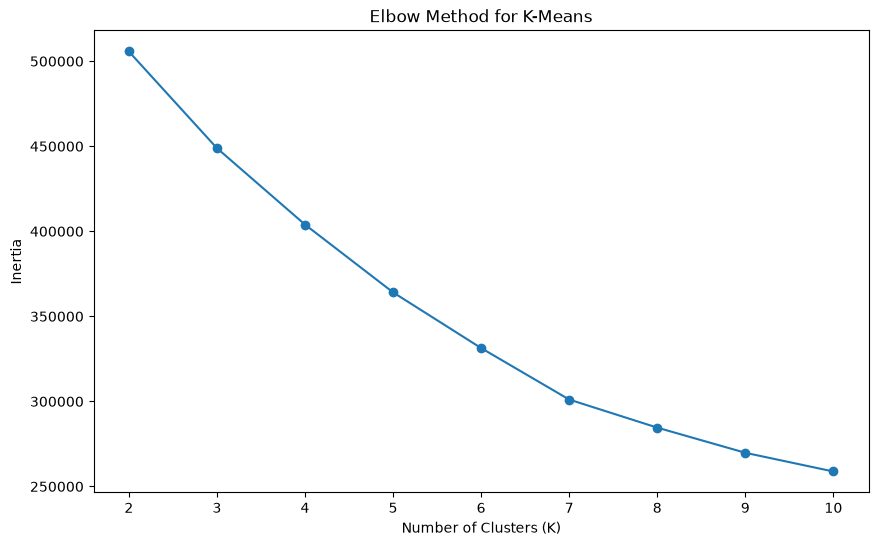

In [59]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    inertia_values,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for K-Means')
plt.xticks(range(2, 11))
plt.show()

In [60]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_train_scaled)

    score = silhouette_score(
        X_train_scaled,
        labels,
        sample_size=5000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.2599
K = 3, Silhouette Score = 0.1607
K = 4, Silhouette Score = 0.1679
K = 5, Silhouette Score = 0.1751
K = 6, Silhouette Score = 0.1864
K = 7, Silhouette Score = 0.1952
K = 8, Silhouette Score = 0.1748
K = 9, Silhouette Score = 0.1780
K = 10, Silhouette Score = 0.1678


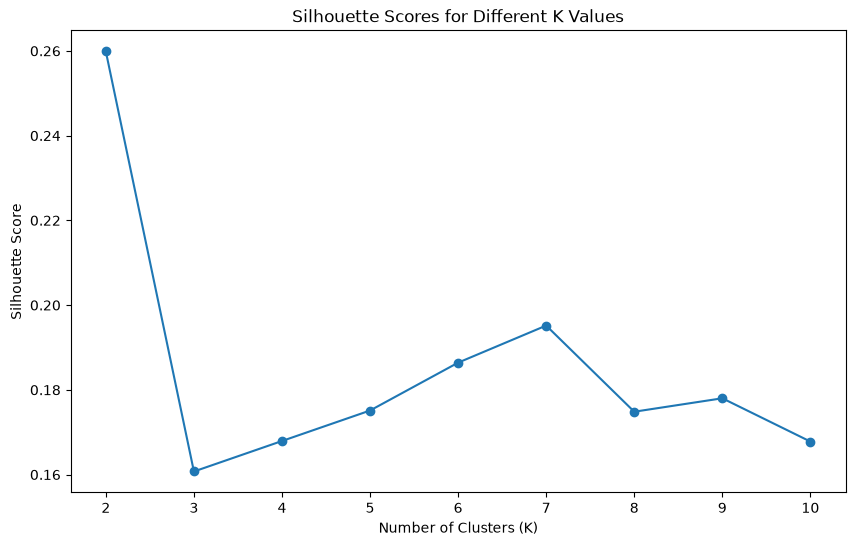

In [61]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores for Different K Values')
plt.xticks(range(2, 11))
plt.show()

### Evaluating the Number of Clusters

The silhouette method was used alongside the elbow method to evaluate different numbers of clusters.

The highest silhouette score was achieved with K=2 (0.2599), suggesting that two clusters provide the strongest overall separation among the configurations tested.

However, K=7 achieved the highest score among configurations with three to ten clusters (0.1952). This is consistent with the elbow analysis, which suggested diminishing returns in inertia reductions beyond approximately seven clusters.

The results highlight a trade-off between cluster separation and the level of detail provided by the model.

Rather than selecting a cluster count based on a single metric, further investigation will compare the characteristics and distributions of the resulting groups.

In [62]:
# Train 3 models and store cluster assignments

cluster_comparisons = {}

for k in [2, 5, 7]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_train_scaled)

    cluster_comparisons[k] = {
        'model': model,
        'labels': labels
    }

In [63]:
for k, results in cluster_comparisons.items():

    print(f"\nK = {k}")

    print(
        pd.Series(results['labels'])
        .value_counts()
        .sort_index()
    )


K = 2
0    53988
1    17804
Name: count, dtype: int64

K = 5
0    16583
1      895
2     5864
3    21516
4    26934
Name: count, dtype: int64

K = 7
0      845
1     5035
2     5256
3     8096
4    16213
5    14431
6    21916
Name: count, dtype: int64


In [64]:
cluster_profiles = {}

for k, results in cluster_comparisons.items():

    # Copy the original training data
    cluster_data = X_train.copy()

    # Add the cluster assignments
    cluster_data['cluster'] = results['labels']

    # Calculate average feature values for each cluster
    profiles = cluster_data.groupby('cluster')[features].mean()

    cluster_profiles[k] = profiles

    print(f"\nAverage audio features for K = {k}")
    print(profiles.round(3))


Average audio features for K = 2
         danceability  energy  acousticness  instrumentalness  valence  \
cluster                                                                  
0               0.596   0.746         0.189             0.122    0.523   
1               0.458   0.294         0.751             0.330    0.304   

           tempo  speechiness  liveness  loudness  
cluster                                            
0        126.306        0.097     0.230    -6.486  
1        109.101        0.059     0.182   -14.650  

Average audio features for K = 5
         danceability  energy  acousticness  instrumentalness  valence  \
cluster                                                                  
0               0.534   0.389         0.667             0.059    0.402   
1               0.575   0.674         0.727             0.008    0.447   
2               0.353   0.197         0.821             0.782    0.180   
3               0.475   0.821         0.068             0

### Interpreting the K-Means Clusters

The average audio features were examined for models containing two, five and seven clusters.

The K=2 model identified a broad distinction between higher-energy, more danceable tracks and lower-energy, more acoustic tracks.

The K=5 model provided additional differentiation, identifying groups with high instrumentalness, high energy and speech-heavy characteristics.

The K=7 model produced more detailed groupings. These included speech-heavy recordings, energetic instrumental tracks, quieter acoustic recordings and highly danceable tracks.

Although K=2 achieved the highest silhouette score, K=7 provided more detailed groupings that may be more useful for a music recommendation system.

K=7 will therefore be retained as a provisional candidate for further evaluation. The final choice will also consider the impact of different scaling methods and the usefulness of the resulting clusters.

In [65]:
robust_comparisons = {}

for k in [2, 5, 7]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_train_robust)

    score = silhouette_score(
        X_train_robust,
        labels,
        sample_size=5000,
        random_state=42
    )

    robust_comparisons[k] = {
        'model': model,
        'labels': labels,
        'silhouette_score': score
    }

    print(
        f"K = {k}, "
        f"RobustScaler Silhouette Score = {score:.4f}"
    )

K = 2, RobustScaler Silhouette Score = 0.5911
K = 5, RobustScaler Silhouette Score = 0.3500
K = 7, RobustScaler Silhouette Score = 0.2398


In [66]:
for k in [2, 5, 7]:

    standard_score = silhouette_score(
        X_train_scaled,
        cluster_comparisons[k]['labels'],
        sample_size=5000,
        random_state=42
    )

    robust_score = robust_comparisons[k]['silhouette_score']

    print(f"\nK = {k}")
    print(f"StandardScaler: {standard_score:.4f}")
    print(f"RobustScaler:   {robust_score:.4f}")


K = 2
StandardScaler: 0.2599
RobustScaler:   0.5911

K = 5
StandardScaler: 0.1751
RobustScaler:   0.3500

K = 7
StandardScaler: 0.1952
RobustScaler:   0.2398


In [67]:
robust_profiles = {}

for k, results in robust_comparisons.items():

    cluster_data = X_train.copy()
    cluster_data['cluster'] = results['labels']

    profiles = cluster_data.groupby('cluster')[features].mean()

    robust_profiles[k] = profiles

    print(f"\nAverage audio features for RobustScaler, K = {k}")
    print(profiles.round(3))


Average audio features for RobustScaler, K = 2
         danceability  energy  acousticness  instrumentalness  valence  \
cluster                                                                  
0               0.578   0.655         0.314             0.020    0.509   
1               0.496   0.547         0.386             0.808    0.304   

           tempo  speechiness  liveness  loudness  
cluster                                            
0        122.786        0.093     0.226    -7.465  
1        118.968        0.066     0.183   -12.809  

Average audio features for RobustScaler, K = 5
         danceability  energy  acousticness  instrumentalness  valence  \
cluster                                                                  
0               0.578   0.627         0.328             0.020    0.508   
1               0.496   0.547         0.387             0.810    0.304   
2               0.654   0.708         0.249             0.018    0.537   
3               0.568   0.698

In [68]:
for k, results in robust_comparisons.items():

    print(f"\nRobustScaler K = {k}")

    cluster_sizes = pd.Series(
        results['labels']
    ).value_counts().sort_index()

    cluster_percentages = (
        cluster_sizes / len(results['labels']) * 100
    )

    cluster_summary = pd.DataFrame({
        'Track Count': cluster_sizes,
        'Percentage': cluster_percentages
    })

    print(cluster_summary.round(2))


RobustScaler K = 2
   Track Count  Percentage
0        57752       80.44
1        14040       19.56

RobustScaler K = 5
   Track Count  Percentage
0        43351       60.38
1        13931       19.40
2         6249        8.70
3          745        1.04
4         7516       10.47

RobustScaler K = 7
   Track Count  Percentage
0        15399       21.45
1         9408       13.10
2          745        1.04
3         4726        6.58
4         5852        8.15
5         4989        6.95
6        30673       42.72


In [69]:
# Examine the smallest RobustScaler K=5 cluster

smallest_cluster = 3

small_cluster_tracks = X_train.copy()

small_cluster_tracks['cluster'] = robust_comparisons[5]['labels']

small_cluster_tracks = small_cluster_tracks[
    small_cluster_tracks['cluster'] == smallest_cluster
]

print(small_cluster_tracks[features].describe().round(3))

       danceability   energy  acousticness  instrumentalness  valence  \
count       745.000  745.000       745.000           745.000  745.000   
mean          0.568    0.698         0.765             0.005    0.428   
std           0.093    0.204         0.178             0.051    0.205   
min           0.252    0.072         0.001             0.000    0.035   
25%           0.505    0.556         0.735             0.000    0.272   
50%           0.567    0.724         0.811             0.000    0.429   
75%           0.627    0.877         0.864             0.000    0.562   
max           0.901    0.995         0.989             0.807    0.964   

         tempo  speechiness  liveness  loudness  
count  745.000      745.000   745.000   745.000  
mean   100.079        0.886     0.699   -11.095  
std     30.342        0.093     0.237     5.071  
min     34.262        0.557     0.046   -31.953  
25%     80.103        0.883     0.641   -14.276  
50%     91.171        0.924     0.752   -1

In [70]:
# Match the cluster labels back to the original track information

cluster_tracks = df_consolidated.loc[
    X_train.index
].copy()

cluster_tracks['cluster'] = robust_comparisons[5]['labels']

print(
    cluster_tracks[
        cluster_tracks['cluster'] == smallest_cluster
    ][['track_name', 'artists', 'track_genre']]
    .head(15)
)

                                         track_name  \
81489                                 The Semicolon   
14534                          Les Maudits français   
81439                             Drinking Fountain   
54858                                      Tv Shows   
57356                                         Intro   
5739                                    Post Office   
65337                                Chapa de Licor   
71378                           Deep Fried Goodness   
76333                                Andrew Jackson   
64554                              Unethical, Pt. 1   
37762                            Sultan of My Heart   
40893                          No Hope, Mormon Tour   
77128                                       Doctors   
46916                            Stubborn Belly Fat   
44362  This Track Is Not Called Something 2 Dance 2   

                                                 artists track_genre  
81489                                        Dan

### Investigation of the Smallest K-Means Cluster

The smallest cluster produced by the RobustScaler K-Means model (K=5) contained 745 tracks, representing approximately 1.04% of the training dataset.

An examination of the track names, artists and genres revealed that the cluster consisted predominantly of comedy and spoken-word recordings. This was supported by its average speechiness score of 0.823, considerably higher than the overall dataset average.

This suggests that K-Means identified a distinct group based on audio characteristics rather than relying on predefined genre labels. Although the cluster also contained a small number of tracks from other genres, its strong association with spoken-word content demonstrates how unsupervised learning can uncover meaningful patterns within music datasets.

In [71]:
# Match cluster labels to the original track information

cluster_tracks = df_consolidated.loc[X_train.index].copy()

cluster_tracks['cluster'] = robust_comparisons[5]['labels']


# Investigate each cluster

for cluster in sorted(cluster_tracks['cluster'].unique()):

    print(f"\n{'='*60}")
    print(f"CLUSTER {cluster}")
    print(f"{'='*60}")

    # Filter tracks belonging to this cluster
    tracks = cluster_tracks[
        cluster_tracks['cluster'] == cluster
    ]

    # Display cluster size
    print(f"\nNumber of tracks: {len(tracks)}")

    # Display average audio features
    print("\nAverage audio features:")
    print(tracks[features].mean().round(3))

    # Display 15 example tracks
    print("\nExample tracks:")
    print(
        tracks[
            ['track_name', 'artists', 'track_genre']
        ].head(15).to_string(index=False)
    )


CLUSTER 0

Number of tracks: 43351

Average audio features:
danceability          0.578
energy                0.627
acousticness          0.328
instrumentalness      0.020
valence               0.508
tempo               122.018
speechiness           0.054
liveness              0.155
loudness             -7.685
dtype: float64

Example tracks:
                     track_name                                           artists                                    track_genre
                 Tudo Outra Vez                                           Canindé                                        [forro]
        Something To Brag About                        George Jones;Tammy Wynette                                   [honky-tonk]
                  Pull Me Under                                         Dimension                                [drum-and-bass]
                   It’s Alright                     Buzz Fuzz;Bass-D;King Matthew                                        [happy]
          

### Interpretation of RobustScaler K-Means Clusters (K=5)

The RobustScaler K-Means model identified five clusters with different audio characteristics.

The cluster profiles and example tracks revealed several patterns:

- **Cluster 0 – General music:** The largest cluster, containing 60.38% of the training data. It includes a diverse range of genres and predominantly vocal music.
- **Cluster 1 – Instrumental music:** Characterised by high instrumentalness (0.810), with examples including classical, meditation and electronic music.
- **Cluster 2 – Rhythm-driven music:** Characterised by relatively high danceability (0.654), energy (0.708) and speechiness (0.287).
- **Cluster 3 – Comedy and spoken-word:** The smallest cluster, containing 1.04% of the training data. Its exceptionally high speechiness (0.886) and example tracks suggest a strong association with comedy and spoken-word recordings.
- **Cluster 4 – Energetic, live-sounding music:** Characterised by high energy (0.769) and liveness (0.604), with several examples of live performances.

Overall, the results suggest that K-Means can identify meaningful groupings based on audio characteristics without using predefined genre labels. However, some clusters are broad and contain multiple genres, demonstrating that audio similarity does not necessarily correspond to genre similarity.

In [72]:
# Create a copy containing the cluster and genre information
genre_data = cluster_tracks[['cluster', 'track_genre']].copy()

# Create one row for each genre associated with a track
genre_data = genre_data.explode('track_genre')

# Check the result
print(genre_data.head(10))

       cluster    track_genre
30418        2     industrial
5875         2          happy
68198        0          forro
57668        0     honky-tonk
71420        0  drum-and-bass
40074        4    world-music
37531        0          happy
4500         4          happy
4500         4         techno
37789        0           goth


In [73]:
# Count how often each genre appears in each cluster
genre_counts = (
    genre_data.groupby(['cluster', 'track_genre'])
    .size()
    .reset_index(name='track_count')
)

# Display the results
print(genre_counts.head(10))

   cluster  track_genre  track_count
0        0     acoustic          744
1        0     afrobeat          439
2        0     alt-rock          647
3        0  alternative          633
4        0      ambient          186
5        0        anime          381
6        0  black-metal          245
7        0    bluegrass          608
8        0        blues          662
9        0       brazil          472


In [74]:
# Get the number of tracks in each cluster
cluster_sizes = cluster_tracks.groupby('cluster').size()

# Calculate the percentage of tracks associated with each genre
genre_counts['percentage'] = genre_counts.apply(
    lambda row: (
        row['track_count'] / cluster_sizes.loc[row['cluster']]
    ) * 100,
    axis=1
)

# Round percentages to 2 decimal places
genre_counts['percentage'] = genre_counts['percentage'].round(2)

In [75]:
for cluster in sorted(genre_counts['cluster'].unique()):

    print(f"\n{'='*50}")
    print(f"CLUSTER {cluster}")
    print(f"{'='*50}")

    top_genres = (
        genre_counts[genre_counts['cluster'] == cluster]
        .sort_values('track_count', ascending=False)
        .head(10)
    )

    print(top_genres.to_string(index=False))


CLUSTER 0
 cluster       track_genre  track_count  percentage
       0          mandopop          770        1.78
       0        songwriter          748        1.73
       0 singer-songwriter          748        1.73
       0          acoustic          744        1.72
       0           country          732        1.69
       0              rock          718        1.66
       0          pop-film          709        1.64
       0          cantopop          708        1.63
       0             salsa          697        1.61
       0        honky-tonk          696        1.61

CLUSTER 1
 cluster    track_genre  track_count  percentage
       1          study          711        5.10
       1 minimal-techno          710        5.10
       1          sleep          655        4.70
       1        new-age          643        4.62
       1 detroit-techno          638        4.58
       1        ambient          623        4.47
       1            idm          612        4.39
       1      

### Genre Distribution and Model Selection

To investigate whether the clusters had meaningful genre associations, the most common genres within each cluster were examined.

The results revealed several interesting patterns:

- **Cluster 0:** Contained a diverse range of genres, with no single genre dominating.
- **Cluster 1:** Included ambient, minimal techno, new-age and study music, consistent with its high instrumentalness.
- **Cluster 2:** Included dancehall, j-dance, hardcore, funk and hip-hop, reflecting its energetic and rhythm-driven audio profile.
- **Cluster 3:** Had a particularly strong association with comedy, which accounted for 85.23% of its tracks. This was consistent with its high speechiness.
- **Cluster 4:** Included several Brazilian music genres, such as pagode, sertanejo and samba, alongside other energetic genres.

These findings suggest that K-Means identified groups based on shared audio characteristics rather than simply separating tracks by their assigned genres. Some clusters had stronger genre associations than others.

### Model Selection

RobustScaler with K=5 was selected as the provisional model because it offered a reasonable balance between cluster separation and interpretability.

Its silhouette score of 0.3500 was higher than the StandardScaler K=5 score of 0.1751. Although K=2 achieved a higher silhouette score of 0.5911, it produced only two broad clusters, whereas K=5 provided more detailed groupings.

The results provide an initial foundation for a music recommendation system, where tracks could be grouped according to their audio characteristics and similar tracks could subsequently be identified within those groups.

The model will next be evaluated using the held-out test dataset to investigate whether the identified clusters remain consistent when applied to previously unseen tracks.

In [76]:
# Evaluate model on test data

# Retrieve the RobustScaler K=5 model
final_model = robust_comparisons[5]['model']

# Assign test tracks to clusters
test_labels = final_model.predict(X_test_robust)

# Check the number of tracks assigned to each cluster
test_cluster_sizes = pd.Series(test_labels).value_counts().sort_index()

print(test_cluster_sizes)

0    10954
1     3470
2     1563
3      184
4     1778
Name: count, dtype: int64


In [77]:
# Create a DataFrame containing the test features
test_cluster_tracks = X_test.copy()

# Add the predicted cluster labels
test_cluster_tracks['cluster'] = test_labels

# Calculate average audio features for each cluster
test_cluster_profiles = (
    test_cluster_tracks.groupby('cluster')[features]
    .mean()
    .round(3)
)

print(test_cluster_profiles)

         danceability  energy  acousticness  instrumentalness  valence  \
cluster                                                                  
0               0.578   0.629         0.330             0.020    0.511   
1               0.504   0.547         0.391             0.809    0.300   
2               0.657   0.717         0.237             0.017    0.541   
3               0.563   0.683         0.751             0.011    0.434   
4               0.512   0.773         0.236             0.023    0.502   

           tempo  speechiness  liveness  loudness  
cluster                                            
0        122.125        0.054     0.153    -7.670  
1        118.824        0.066     0.187   -12.638  
2        127.247        0.285     0.207    -6.650  
3        101.626        0.881     0.688   -11.672  
4        126.268        0.076     0.600    -6.366  


In [78]:
# Calculate silhouette score on the test dataset
test_silhouette = silhouette_score(
    X_test_robust,
    test_labels,
    sample_size=5000,
    random_state=42
)

print(f"Test silhouette score: {test_silhouette:.4f}")

Test silhouette score: 0.3497


### Evaluation on the Test Dataset

The fitted RobustScaler K=5 model was evaluated using the held-out test dataset to investigate whether the identified clusters remained consistent when applied to previously unseen tracks.

The predicted test cluster sizes were very similar to the training cluster sizes. Each cluster retained approximately the same proportion of tracks, suggesting that the model consistently assigns tracks to its five groups.

The average audio characteristics of the test clusters were also compared with the training cluster profiles. The results showed very similar values across all nine audio features.

In particular:
- Cluster 1 retained a high average instrumentalness of approximately 0.81.
- Cluster 2 retained relatively high danceability and energy.
- Cluster 3 retained very high speechiness, at approximately 0.88.
- Cluster 4 retained high energy and liveness.

The silhouette score was also calculated on the test dataset using a sample of 5,000 observations.

| Dataset | Silhouette score |
|---|---:|
| Training | 0.3500 |
| Test | 0.3497 |

The almost identical scores indicate that the model maintained a similar level of cluster separation on previously unseen data.

Overall, these results provide encouraging evidence that RobustScaler K=5 has identified relatively stable groupings based on audio characteristics. Although the silhouette score indicates some overlap between clusters, the consistency of the results supports retaining this model for the next stage of the project.

In [79]:
# Building the recommendation mechanism 

# Start with all consolidated track information
recommendation_data = df_consolidated.copy()

# Transform all audio features using the fitted RobustScaler
X_all_robust = robust_scaler.transform(
    recommendation_data[features]
)

# Assign each track to a cluster using the fitted K-Means model
recommendation_data['cluster'] = final_model.predict(
    X_all_robust
)

# Check the result
print(recommendation_data.shape)
print(recommendation_data['cluster'].value_counts().sort_index())

(89741, 21)
cluster
0    54305
1    17401
2     7812
3      929
4     9294
Name: count, dtype: int64


In [80]:
print(
    recommendation_data[
        ['track_name', 'artists', 'track_genre', 'cluster']
    ].head()
)

                                          track_name  \
0                                              Lolly   
1  It's All Coming Back To Me Now (Glee Cast Vers...   
2                      Böxig Leise - Pig & Dan Remix   
3                                         Teeje Week   
4                                               Tief   

                    artists       track_genre  cluster  
0                      Rill          [german]        2  
1                 Glee Cast            [club]        0  
2  Paul Kalkbrenner;Pig&Dan  [minimal-techno]        0  
3             Jordan Sandhu         [hip-hop]        2  
4          Paul Kalkbrenner  [minimal-techno]        1  


In [81]:
# Extract the audio features from the full dataset
recommendation_features = robust_scaler.transform(
    recommendation_data[features]
)

print(recommendation_features.shape)

(89741, 9)


In [82]:
from sklearn.metrics.pairwise import cosine_similarity

track_a = recommendation_features[0]
track_b = recommendation_features[1]

similarity = cosine_similarity(
    [track_a],
    [track_b]
)

print(similarity)

[[-0.41223593]]


In [83]:
# RobustScaler was used, some feature values are negative - cosine similarity can also be negative, doesn't necessarily mean musically incompatible. 

In [84]:
import numpy as np

# Select the first track
track_index = 0

# Find the cluster this track belongs to
selected_cluster = recommendation_data.iloc[track_index]['cluster']

# Find the positions of all tracks in the same cluster
candidate_indices = np.where(
    recommendation_data['cluster'].to_numpy() == selected_cluster
)[0]

# Remove the selected track from the candidates
candidate_indices = candidate_indices[
    candidate_indices != track_index
]

print("Selected track:")
print(recommendation_data.iloc[track_index]['track_name'])

print("\nNumber of candidate tracks:")
print(len(candidate_indices))

Selected track:
Lolly

Number of candidate tracks:
7811


In [85]:
# Calculate similarity between the selected track and every candidate
similarities = cosine_similarity(
    [recommendation_features[track_index]],
    recommendation_features[candidate_indices]
).flatten()

# Display the first 10 similarity scores
print(similarities[:10])

[0.71618399 0.76944022 0.84619914 0.95740518 0.79251031 0.8618917
 0.89092853 0.58003471 0.55906875 0.89151469]


In [86]:
# Find the positions of the five highest similarity scores
top_positions = np.argsort(similarities)[::-1][:5]

# Get the corresponding track positions
recommended_indices = candidate_indices[top_positions]

# Display the recommended tracks
recommendations = recommendation_data.iloc[
    recommended_indices
][['track_name', 'artists', 'track_genre']].copy()

# Add their similarity scores
recommendations['similarity'] = similarities[top_positions]

print(recommendations)

                      track_name                          artists  \
74548                   Marathon            Connor Price;4Korners   
60561      Straight Outta Kerala         Kalla Sha;Vkdkv;Vaidhyan   
82625                    Droptop  AP Dhillon;Gurinder Gill;Gminxr   
69615  Mind Playing Tricks on Me                        Geto Boys   
89027                Bittersweet                   Michael Calfan   

                           track_genre  similarity  
74548                            [sad]    0.984470  
60561                          [malay]    0.982669  
82625                        [hip-hop]    0.980197  
69615                       [hardcore]    0.979887  
89027  [deep-house, progressive-house]    0.979747  


In [87]:
# Display the audio features of the selected track and recommendations
comparison = recommendation_data.iloc[
    [track_index] + recommended_indices.tolist()
][['track_name', 'artists'] + features]

print(comparison.T)

                    0                      74548                     60561  \
track_name          Lolly               Marathon     Straight Outta Kerala   
artists              Rill  Connor Price;4Korners  Kalla Sha;Vkdkv;Vaidhyan   
danceability         0.91                  0.855                     0.929   
energy              0.374                  0.405                      0.49   
acousticness       0.0757                 0.0415                    0.0303   
instrumentalness  0.00301               0.000008                  0.000007   
valence             0.432                  0.522                     0.276   
tempo             104.042                 87.007                   110.134   
speechiness         0.199                  0.199                     0.201   
liveness            0.154                  0.209                    0.0808   
loudness           -9.844                -10.189                   -10.382   

                                            82625              

### Initial Recommendation Mechanism: Cosine Similarity

To demonstrate how the clustering model could support music recommendations, cosine similarity was used to identify tracks with similar audio characteristics.

**Initial results**

Using *Lolly* by Rill as the example input, the system returned five recommendations with cosine similarity scores ranging from 0.9797 to 0.9845.

The recommendations shared several audio characteristics with the original track, particularly danceability, instrumentalness and speechiness. However, there were noticeable differences in some features, including tempo and acousticness.

**Limitations**

Cosine similarity measures the directional similarity of feature vectors rather than the absolute distance between individual feature values. Consequently, high similarity scores do not necessarily indicate that tracks have closely matching values across all audio features.

The initial results demonstrate that the recommendation mechanism is functioning, but further evaluation is needed to determine whether another similarity measure could produce more closely matched recommendations.

In [88]:
from sklearn.metrics.pairwise import euclidean_distances

# Calculate Euclidean distances
distances = euclidean_distances(
    [recommendation_features[track_index]],
    recommendation_features[candidate_indices]
).flatten()

# Display the first 10 distances
print(distances[:10])

[2.53530696 6.10462496 2.5794669  4.22769202 3.49924111 2.69105403
 4.43289488 3.02185547 3.66909471 4.86432074]


In [89]:
# Find the positions of the five smallest distances
top_positions_euclidean = np.argsort(distances)[:5]

# Get the corresponding track positions
recommended_indices_euclidean = candidate_indices[
    top_positions_euclidean
]

# Display the recommended tracks
euclidean_recommendations = recommendation_data.iloc[
    recommended_indices_euclidean
][['track_name', 'artists', 'track_genre']].copy()

# Add their Euclidean distances
euclidean_recommendations['distance'] = distances[
    top_positions_euclidean
]

print(euclidean_recommendations)

                  track_name                   artists track_genre  distance
74548               Marathon     Connor Price;4Korners       [sad]  0.612416
60561  Straight Outta Kerala  Kalla Sha;Vkdkv;Vaidhyan     [malay]  0.652451
2458              A l'envers                    Django    [french]  0.759737
28843        Raheem Sterling     Teebone;Countree Hype   [j-dance]  0.770432
13175           Come On Girl       Reggie P;Toya Brown     [blues]  0.774106


In [90]:
# Compare the original track with Euclidean recommendations
euclidean_comparison = recommendation_data.iloc[
    [track_index] + recommended_indices_euclidean.tolist()
][['track_name', 'artists'] + features]

print(euclidean_comparison.T)

                    0                      74548                     60561  \
track_name          Lolly               Marathon     Straight Outta Kerala   
artists              Rill  Connor Price;4Korners  Kalla Sha;Vkdkv;Vaidhyan   
danceability         0.91                  0.855                     0.929   
energy              0.374                  0.405                      0.49   
acousticness       0.0757                 0.0415                    0.0303   
instrumentalness  0.00301               0.000008                  0.000007   
valence             0.432                  0.522                     0.276   
tempo             104.042                 87.007                   110.134   
speechiness         0.199                  0.199                     0.201   
liveness            0.154                  0.209                    0.0808   
loudness           -9.844                -10.189                   -10.382   

                       2458                   28843            

### Comparing Similarity Measures: Cosine Similarity vs Euclidean Distance

To investigate whether different similarity measures produce different recommendations, cosine similarity and Euclidean distance were compared using the same selected track (*Lolly* by Rill) and the same candidate pool of 7,811 tracks.

**Results**

Both methods identified *Marathon* and *Straight Outta Kerala* as the two strongest recommendations.

However, the remaining recommendations differed:

- Cosine similarity favoured *Droptop*, *Mind Playing Tricks on Me* and *Bittersweet*.
- Euclidean distance favoured *A l'envers*, *Raheem Sterling* and *Come On Girl*.

**Comparison**

Cosine similarity compares the direction of feature vectors, whereas Euclidean distance measures the straight-line distance between their scaled feature values.

Inspecting the original audio features showed that the Euclidean recommendations generally had reasonably similar characteristics to the selected track, particularly in danceability, instrumentalness and speechiness.

**Initial conclusion**

Both methods are capable of identifying tracks with similar audio characteristics. Euclidean distance is a promising alternative because it considers the absolute differences between individual scaled features.

Further testing across multiple tracks is required before selecting the final similarity measure.

In [91]:
# Find the first track belonging to cluster 1
track_index_2 = np.where(
    recommendation_data['cluster'].to_numpy() == 1
)[0][0]

print(
    recommendation_data.iloc[track_index_2][
        ['track_name', 'artists', 'track_genre']
    ]
)

track_name                 Tief
artists        Paul Kalkbrenner
track_genre    [minimal-techno]
Name: 4, dtype: object


In [92]:
# Find all tracks belonging to the selected track's cluster
selected_cluster_2 = recommendation_data.iloc[
    track_index_2
]['cluster']

candidate_indices_2 = np.where(
    recommendation_data['cluster'].to_numpy() == selected_cluster_2
)[0]

# Exclude the selected track
candidate_indices_2 = candidate_indices_2[
    candidate_indices_2 != track_index_2
]

print("Selected track:", recommendation_data.iloc[track_index_2]['track_name'])
print("Number of candidates:", len(candidate_indices_2))

Selected track: Tief
Number of candidates: 17400


In [93]:
# Calculate cosine similarity
similarities_2 = cosine_similarity(
    [recommendation_features[track_index_2]],
    recommendation_features[candidate_indices_2]
).flatten()

# Calculate Euclidean distance
distances_2 = euclidean_distances(
    [recommendation_features[track_index_2]],
    recommendation_features[candidate_indices_2]
).flatten()

print("First 10 cosine similarity scores:")
print(similarities_2[:10])

print("\nFirst 10 Euclidean distances:")
print(distances_2[:10])

First 10 cosine similarity scores:
[0.9718577  0.93685992 0.91500073 0.94234943 0.95311127 0.96467844
 0.98207463 0.84539136 0.9759842  0.98384314]

First 10 Euclidean distances:
[2.14799922 2.90288396 5.71993178 2.75657145 2.82112494 3.76665487
 1.81273814 5.20794788 2.79216997 2.21718875]


In [94]:
# Get the five highest cosine similarity scores
top_positions_cosine_2 = np.argsort(similarities_2)[::-1][:5]

# Get the corresponding track indices
recommended_indices_cosine_2 = candidate_indices_2[
    top_positions_cosine_2
]

# Get the five lowest Euclidean distances
top_positions_euclidean_2 = np.argsort(distances_2)[:5]

# Get the corresponding track indices
recommended_indices_euclidean_2 = candidate_indices_2[
    top_positions_euclidean_2
]

# Display cosine recommendations
cosine_recommendations_2 = recommendation_data.iloc[
    recommended_indices_cosine_2
][['track_name', 'artists', 'track_genre']].copy()

cosine_recommendations_2['similarity'] = similarities_2[
    top_positions_cosine_2
]

print("COSINE SIMILARITY RECOMMENDATIONS")
print(cosine_recommendations_2)

# Display Euclidean recommendations
euclidean_recommendations_2 = recommendation_data.iloc[
    recommended_indices_euclidean_2
][['track_name', 'artists', 'track_genre']].copy()

euclidean_recommendations_2['distance'] = distances_2[
    top_positions_euclidean_2
]

print("\nEUCLIDEAN DISTANCE RECOMMENDATIONS")
print(euclidean_recommendations_2)

COSINE SIMILARITY RECOMMENDATIONS
             track_name         artists        track_genre  similarity
48625        Weightless   The Gathering             [goth]    0.998921
84209           Reverie   Sleep Surgeon  [ambient, guitar]    0.998634
81138               Sol    Solar Fields          [ambient]    0.998327
67280  Fox on a Mission     Lorne Balfe          [british]    0.998252
711               Cells  Infinite Scale              [idm]    0.998040

EUCLIDEAN DISTANCE RECOMMENDATIONS
                                           track_name  \
39430                               I'll Wait Forever   
36878                                        Nascency   
46894                                       Collapsed   
67797  Black Out Days - Future Islands Remix (Slowed)   
34399                                       Aliceband   

                                                 artists   track_genre  \
39430                                            Ex-Voto        [goth]   
36878        

In [95]:
# Compare Tief with its cosine recommendations
cosine_comparison_2 = recommendation_data.iloc[
    [track_index_2] + recommended_indices_cosine_2.tolist()
][['track_name', 'artists'] + features]

print("COSINE FEATURE COMPARISON")
print(cosine_comparison_2.T)

# Compare Tief with its Euclidean recommendations
euclidean_comparison_2 = recommendation_data.iloc[
    [track_index_2] + recommended_indices_euclidean_2.tolist()
][['track_name', 'artists'] + features]

print("\nEUCLIDEAN FEATURE COMPARISON")
print(euclidean_comparison_2.T)

COSINE FEATURE COMPARISON
                             4              48625          84209  \
track_name                    Tief     Weightless        Reverie   
artists           Paul Kalkbrenner  The Gathering  Sleep Surgeon   
danceability                 0.519          0.549          0.467   
energy                       0.431          0.431          0.392   
acousticness              0.000964          0.166          0.023   
instrumentalness              0.72          0.626          0.913   
valence                      0.234          0.265          0.038   
tempo                      129.971        124.035          135.0   
speechiness                 0.0291         0.0331         0.0336   
liveness                    0.0916          0.107          0.107   
loudness                   -13.606        -13.118        -14.282   

                         81138             67280           711    
track_name                 Sol  Fox on a Mission           Cells  
artists           Solar

### Building a Reusable Music Recommendation Function

Following the comparison of cosine similarity and Euclidean distance, Euclidean distance was provisionally selected as the recommendation measure.

The recommendation process will now be consolidated into a reusable Python function. This will allow recommendations to be generated for different tracks without repeating the individual calculations.

In [96]:
def recommend_tracks(track_index, number_of_recommendations=5):

    # Retrieve the selected track
    selected_track = recommendation_data.iloc[track_index]

    # Identify its cluster
    selected_cluster = selected_track['cluster']

    # Find all tracks belonging to the same cluster
    candidate_indices = np.where(
        recommendation_data['cluster'].to_numpy() == selected_cluster
    )[0]

    # Identify the selected track's artists
    selected_artists = set(
        selected_track['artists'].split(';')
    )

    # Retrieve the artists of the candidate tracks
    candidate_artists = (
        recommendation_data.iloc[candidate_indices]['artists']
        .fillna('')
        .str.split(';')
    )

    # Exclude tracks containing any of the selected artists
    keep_mask = ~candidate_artists.apply(
        lambda artists: bool(selected_artists.intersection(artists))
    ).to_numpy()

    candidate_indices = candidate_indices[keep_mask]

    # Calculate Euclidean distances
    distances = euclidean_distances(
        [recommendation_features[track_index]],
        recommendation_features[candidate_indices]
    ).flatten()

    # Sort candidate tracks by Euclidean distance
    sorted_positions = np.argsort(distances)
    
    # Store the selected recommendation indices
    recommended_indices = []
    recommended_artists = set()
    
    # Select recommendations while avoiding repeated artists
    for position in sorted_positions:
    
        candidate_index = candidate_indices[position]
    
        candidate_track = recommendation_data.iloc[candidate_index]
    
        candidate_artist_list = set(
            candidate_track['artists'].split(';')
        )
    
        # Skip tracks containing an already recommended artist
        if recommended_artists.intersection(candidate_artist_list):
            continue
    
        recommended_indices.append(candidate_index)
    
        recommended_artists.update(candidate_artist_list)
    
        # Stop once the requested number has been reached
        if len(recommended_indices) == number_of_recommendations:
            break
    
    # Retrieve the recommended tracks
    recommendations = recommendation_data.iloc[
        recommended_indices
    ][['track_name', 'artists', 'track_genre']].copy()
    
    # Add their Euclidean distances
    recommendations['distance'] = [
        distances[np.where(candidate_indices == index)[0][0]]
        for index in recommended_indices
    ]
    
    return recommendations

recommend_tracks(0)

,track_name,artists,track_genre,distance
74548,Marathon,Connor Price;4Korners,[sad],0.612416
60561,Straight Outta Kerala,Kalla Sha;Vkdkv;Vaidhyan,[malay],0.652451
2458,A l'envers,Django,[french],0.759737
28843,Raheem Sterling,Teebone;Countree Hype,[j-dance],0.770432
13175,Come On Girl,Reggie P;Toya Brown,[blues],0.774106


In [97]:
recommend_tracks(4)

,track_name,artists,track_genre,distance
39430,I'll Wait Forever,Ex-Voto,[goth],0.635542
36878,Nascency,MIKTEK,[idm],0.716025
46894,Collapsed,Lights Of Euphoria,[industrial],0.716379
67797,Black Out Days - Future Islands Remix (Slowed),Phantogram;xxtristanxo;Slowed Radio;Future Isl...,[indie],0.721601
34399,Aliceband,Stumbleine,[idm],0.725554


In [98]:
track_name = "Tief"
artist_name = "Paul Kalkbrenner"

matches = recommendation_data[
    (recommendation_data['track_name'].str.lower() == track_name.lower()) &
    (recommendation_data['artists'].str.lower() == artist_name.lower())
]

matches[['track_name', 'artists', 'track_genre', 'cluster']]

,track_name,artists,track_genre,cluster
4,Tief,Paul Kalkbrenner,[minimal-techno],1


In [99]:
track_index = matches.index[0]

print("Track index:", track_index)

recommend_tracks(track_index)

Track index: 4


,track_name,artists,track_genre,distance
39430,I'll Wait Forever,Ex-Voto,[goth],0.635542
36878,Nascency,MIKTEK,[idm],0.716025
46894,Collapsed,Lights Of Euphoria,[industrial],0.716379
67797,Black Out Days - Future Islands Remix (Slowed),Phantogram;xxtristanxo;Slowed Radio;Future Isl...,[indie],0.721601
34399,Aliceband,Stumbleine,[idm],0.725554


In [100]:
def recommend_by_track(track_name, artist_name, match_index=None):
    
    # Search for the track and artist
    matches = recommendation_data[
        (recommendation_data['track_name'].str.lower() == track_name.lower()) &
        (recommendation_data['artists'].str.lower() == artist_name.lower())
    ]

    if matches.empty:
        print("Track not found. Please check the track name and artist.")
        return

    # Check for multiple matching tracks
    if len(matches) > 1 and match_index is None:
        print("Multiple matches found. Please select a track using its index:")
        print(matches[['track_name', 'artists', 'track_genre', 'cluster']])
        return

    # Validate the selected index
    if match_index is not None:
        if match_index not in matches.index:
            print("Invalid selection. Please choose an index from the results.")
            return
        track_index = match_index

    # Retrieve the matching track's index if not already selected
    if match_index is None:
        track_index = matches.index[0]

    # Generate recommendations
    return recommend_tracks(track_index)
    
recommend_by_track("Tief", "Paul Kalkbrenner")

#recommend_by_track("Unknown Track", "Unknown Artist")

,track_name,artists,track_genre,distance
39430,I'll Wait Forever,Ex-Voto,[goth],0.635542
36878,Nascency,MIKTEK,[idm],0.716025
46894,Collapsed,Lights Of Euphoria,[industrial],0.716379
67797,Black Out Days - Future Islands Remix (Slowed),Phantogram;xxtristanxo;Slowed Radio;Future Isl...,[indie],0.721601
34399,Aliceband,Stumbleine,[idm],0.725554


In [101]:
recommend_by_track("Lolly", "Rill")

,track_name,artists,track_genre,distance
74548,Marathon,Connor Price;4Korners,[sad],0.612416
60561,Straight Outta Kerala,Kalla Sha;Vkdkv;Vaidhyan,[malay],0.652451
2458,A l'envers,Django,[french],0.759737
28843,Raheem Sterling,Teebone;Countree Hype,[j-dance],0.770432
13175,Come On Girl,Reggie P;Toya Brown,[blues],0.774106


In [102]:
recommendation_data[
    recommendation_data['cluster'] == 3
][['track_name', 'artists', 'track_genre']].head(10)

,track_name,artists,track_genre
5,Thanksgiving Chicken,Chad Daniels,[comedy]
29,It's a Prison Workout,Iliza Shlesinger,[comedy]
114,Lazy (It Runs in the Family),Big Jay Oakerson,[comedy]
143,My Rehab Counselor,Artie Lange,[comedy]
154,Arizona,Jessi Campbell,[comedy]
417,Prostitution Should Be Legal,Josh Wagner,[comedy]
449,Explode Coração - Ao Vivo,Maria Bethânia,[samba]
488,The Realism of Expression,Ben Bailey,[comedy]
499,Rocket Launcher Body Sounds - Live,Jeff Foxworthy,[comedy]
511,My Dad Is Athletic,Anjelah Johnson,[comedy]


In [103]:
recommend_by_track("My Rehab Counselor", "Artie Lange")

,track_name,artists,track_genre,distance
34481,Relationships,Todd Glass,[comedy],0.833950
63387,The Promise of Sleep,Mike Birbiglia,[comedy],0.843268
87092,It Is Written,Doug Benson,[comedy],0.862738
73375,"Web MD, Uso Tour",Kathleen Madigan,[comedy],0.878113
16775,Corn Syrup,Kyle Kinane,[comedy],0.911603


In [104]:
recommendation_data[
    recommendation_data['cluster'] == 0
][['track_name', 'artists', 'track_genre']].head(10)

,track_name,artists,track_genre
1,It's All Coming Back To Me Now (Glee Cast Vers...,Glee Cast,[club]
2,Böxig Leise - Pig & Dan Remix,Paul Kalkbrenner;Pig&Dan,[minimal-techno]
6,Better,Pink Sweat$;Kirby,"[chill, soul]"
7,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,"[punk-rock, ska]"
8,Poor Man,Old Crow Medicine Show,[bluegrass]
10,Find Me - Sigma VIP Remix,Sigma;Birdy,[drum-and-bass]
12,Mr. Brightside,The Killers,"[alt-rock, alternative, rock]"
13,Sandwiches de Miga,Pappo's Blues,[punk-rock]
14,Lovemark,Ouse;Powfu,"[emo, sad]"
15,Mister Love,Ernest Tubb;The Wilburn Brothers,[honky-tonk]


In [105]:
recommend_by_track("Böxig Leise - Pig & Dan Remix", "Paul Kalkbrenner;Pig&Dan")

,track_name,artists,track_genre,distance
50439,I've Been Feeling,Bjarne Hendrik,[french],0.376535
73057,Addio Addio - Original,Kollektiv Turmstrasse,[minimal-techno],0.569158
69764,Your Love Gives Me Gravity (feat. Planningtorock),Solomun;Jam Rostron,[minimal-techno],0.650547
48388,Empty Floor,Jan Blomqvist,"[deep-house, minimal-techno]",0.716125
31410,What Else Is There? - ARTBAT Remix,Röyksopp;ARTBAT,[trip-hop],0.727257


In [106]:
recommendation_data[
    recommendation_data['cluster'] == 4
][['track_name', 'artists', 'track_genre']].head(10)

,track_name,artists,track_genre
22,Finish Line,Logistics;Zara Kershaw,[drum-and-bass]
24,Yemyeşil Bir Deniz,İlhan İrem,"[j-pop, j-rock, jazz, turkish]"
30,Derê / Vício / Nuvem - Ao Vivo,Belo,[pagode]
80,Lloró Como una Mujer (with Leopoldo Federico y...,Julio Sosa;Leopoldo Federico y su Orquesta,[tango]
83,Schizophrenic - Remastered 2019,Rotterdam Terror Corps,[happy]
91,Já Tentei,Exaltasamba,"[pagode, samba]"
93,Hardcore To Da Bone - 2012 Edit,Masters of Ceremony,[happy]
98,I Gotta Feeling,Black Eyed Peas,[dance]
99,With My Hands Lifted High,Gersson Edinbaro,[malay]
101,Misery Leech,Ingested,[death-metal]


In [107]:
recommend_by_track("Misery Leech", "Ingested")

,track_name,artists,track_genre,distance
10797,Elokuutio,Stam1na,[heavy-metal],0.416704
40169,Extreme Terror - Chaotic Hostility Remix,Dj Skinhead;Chaotic Hostility,[happy],0.431473
15997,Tsunami,Escape The Day,"[metalcore, swedish, trance]",0.447133
27567,Blah Blah Blah (Mixed),Armin van Buuren,[trance],0.460388
80314,No Way Out,Bullet For My Valentine,[metalcore],0.464967


In [108]:
duplicate_tracks = recommendation_data[
    recommendation_data.duplicated(
        subset=['track_name', 'artists'],
        keep=False
    )
]

duplicate_tracks[
    ['track_name', 'artists', 'track_genre', 'cluster']
].sort_values(['track_name', 'artists'])

,track_name,artists,track_genre,cluster
653,"""Was He Slow?"" - Music From The Motion Picture...",Kid Koala,[trip-hop],2
14472,"""Was He Slow?"" - Music From The Motion Picture...",Kid Koala,[trip-hop],2
416,'Til You Can't,Cody Johnson,[country],0
8906,'Til You Can't,Cody Johnson,[country],0
26568,'Til You Can't,Cody Johnson,[country],0
...,...,...,...,...
87791,風に吹かれても,Keyakizaka46,[j-idol],0
66468,風立ちぬ(SEIKO STORY〜80's HITS COLLECTION〜),Seiko Matsuda,"[j-idol, techno]",0
68544,風立ちぬ(SEIKO STORY〜80's HITS COLLECTION〜),Seiko Matsuda,"[j-idol, techno]",0
15642,麻痺,yama,[j-pop],4


In [109]:
recommend_by_track("Lolly", "Rill")

,track_name,artists,track_genre,distance
74548,Marathon,Connor Price;4Korners,[sad],0.612416
60561,Straight Outta Kerala,Kalla Sha;Vkdkv;Vaidhyan,[malay],0.652451
2458,A l'envers,Django,[french],0.759737
28843,Raheem Sterling,Teebone;Countree Hype,[j-dance],0.770432
13175,Come On Girl,Reggie P;Toya Brown,[blues],0.774106


In [110]:
#Evaluate recommendation quality

track_index = 4

recommended_tracks = recommend_tracks(track_index)

selected_features = recommendation_data.iloc[track_index][features]

recommended_features = recommendation_data.loc[
    recommended_tracks.index, features
]

comparison = recommended_features.copy()

comparison.loc['Selected track'] = selected_features

comparison

,danceability,energy,acousticness,instrumentalness,valence,tempo,speechiness,liveness,loudness
39430,0.484,0.589,0.000522,0.739,0.2030,124.949,0.0309,0.1540,-12.470
36878,0.592,0.554,0.030700,0.768,0.1760,140.024,0.0280,0.1050,-13.448
46894,0.614,0.658,0.009330,0.711,0.2500,132.006,0.0333,0.1040,-13.187
67797,0.535,0.402,0.000748,0.734,0.0862,142.847,0.0310,0.0812,-10.884
34399,0.478,0.421,0.000890,0.761,0.0732,142.517,0.0357,0.1310,-12.752
Selected track,0.519,0.431,0.000964,0.720,0.2340,129.971,0.0291,0.0916,-13.606


In [111]:
# Retrieve the scaled features of the selected track
selected_scaled = recommendation_features[track_index]

# Retrieve the scaled features of the recommended tracks
recommended_scaled = recommendation_features[
    recommended_tracks.index.to_numpy()
]

# Calculate absolute differences between each recommendation and the selected track
scaled_comparison = pd.DataFrame(
    np.abs(recommended_scaled - selected_scaled),
    columns=features,
    index=recommended_tracks.index
)

# Calculate the average difference across all nine features
scaled_comparison['mean_difference'] = scaled_comparison.mean(axis=1)

# Display recommendations from most to least similar
scaled_comparison.sort_values('mean_difference')

,danceability,energy,acousticness,instrumentalness,valence,tempo,speechiness,liveness,loudness,mean_difference
46894,0.392562,0.573232,0.013737,0.091371,0.037037,0.049792,0.084,0.068282,0.079947,0.154440
39430,0.144628,0.398990,0.000726,0.192893,0.071759,0.122877,0.036,0.343612,0.216753,0.169804
67797,0.066116,0.073232,0.000355,0.142132,0.342130,0.315046,0.038,0.057269,0.519367,0.172627
36878,0.301653,0.310606,0.048828,0.487310,0.134259,0.245974,0.022,0.073789,0.030147,0.183840
34399,0.169421,0.025253,0.000122,0.416244,0.372222,0.306971,0.132,0.216960,0.162946,0.200238


In [112]:
# Displays 3 randomly selected tracks from each cluster - we can then choose one from each and build a small evaluation process around them. 

for cluster in sorted(recommendation_data['cluster'].unique()):
    print(f"\nCluster {cluster}")

    print(
        recommendation_data[
            recommendation_data['cluster'] == cluster
        ][['track_name', 'artists', 'track_genre']]
        .sample(3, random_state=42)
    )


Cluster 0
            track_name             artists    track_genre
15667        Small Axe  Greensky Bluegrass    [bluegrass]
78520         Sparrows         Cory Asbury  [world-music]
55856  Cumbia Caletera             Billo's        [salsa]

Cluster 1
                       track_name               artists    track_genre
30557                       Ze-Ka  Yimino;Baccara Smart          [idm]
41805                  The Prayer     Electric Universe       [trance]
75514  As the Wounds Gently Bleed           Këkht Aräkh  [black-metal]

Cluster 2
                               track_name                   artists  \
45354  Heavy and Dark - Carasel Vocal Mix  Serum;MC Bassman;Carasel   
84875           Let Yourself Go - Mix Cut                  El Bruto   
70323         Dreams (Back to 2005 Remix)                Technikore   

           track_genre  
45354  [drum-and-bass]  
84875          [happy]  
70323          [happy]  

Cluster 3
                             track_name           artis

In [113]:
# Select one test track from each cluster
test_tracks = {
    0: 15667,
    1: 30557,
    2: 45354,
    3: 2494,
    4: 61972
}

# Generate recommendations for each selected track
for cluster, track_index in test_tracks.items():

    selected_track = recommendation_data.iloc[track_index]

    print(f"\nCluster {cluster}")
    print(
        f"Selected track: {selected_track['track_name']} "
        f"by {selected_track['artists']}"
    )

    print(recommend_tracks(track_index))


Cluster 0
Selected track: Small Axe by Greensky Bluegrass
                                track_name         artists    track_genre  \
57800                         No Está Aquí   Los Hooligans  [rock-n-roll]   
15254                      Help Me, Rhonda  The Beach Boys   [psych-rock]   
44380                       Necesito De Ti    Grupo Azteka         [folk]   
9120   Have You Ever Needed Someone So Bad     Def Leppard    [hard-rock]   
77640                    Come Give Me Love   Ted Gärdestad      [swedish]   

       distance  
57800  0.476368  
15254  0.513946  
44380  0.561528  
9120   0.576743  
77640  0.618543  

Cluster 1
Selected track: Ze-Ka by Yimino;Baccara Smart
              track_name                      artists          track_genre  \
82132  Infinite Bookends                        Ochre                [idm]   
29171            Roygbiv             Boards of Canada  [ambient, trip-hop]   
39017      Blue Sapphire  Sarah, the Illstrumentalist              [study]   
5

In [114]:
# Numerical comparisons

for cluster, track_index in test_tracks.items():

    selected_track = recommendation_data.iloc[track_index]

    recommended_tracks = recommend_tracks(track_index)

    selected_genres = set(selected_track['track_genre'])

    print(f"\nCluster {cluster}")
    print(f"Selected genres: {selected_genres}")

    for _, track in recommended_tracks.iterrows():

        recommended_genres = set(track['track_genre'])

        shared_genres = selected_genres.intersection(
            recommended_genres
        )

        print(
            f"{track['track_name']}: "
            f"Shared genres = {shared_genres}"
        )


Cluster 0
Selected genres: {'bluegrass'}
No Está Aquí: Shared genres = set()
Help Me, Rhonda: Shared genres = set()
Necesito De Ti: Shared genres = set()
Have You Ever Needed Someone So Bad: Shared genres = set()
Come Give Me Love: Shared genres = set()

Cluster 1
Selected genres: {'idm'}
Infinite Bookends: Shared genres = {'idm'}
Roygbiv: Shared genres = set()
Blue Sapphire: Shared genres = set()
A Jar of Legos: Shared genres = set()
Gak (Remastered): Shared genres = set()

Cluster 2
Selected genres: {'drum-and-bass'}
Blow the Speakers: Shared genres = set()
Beginning Of Time: Shared genres = set()
Crime, Violence & Power: Shared genres = set()
Verano En París - Remix: Shared genres = set()
Believe It: Shared genres = set()

Cluster 3
Selected genres: {'comedy'}
Showering Is An Event: Shared genres = {'comedy'}
Kayaking: Shared genres = {'comedy'}
The Hudson River Challenge: Shared genres = {'comedy'}
Potheads: Shared genres = {'comedy'}
Psycho Women / Species: Shared genres = {'come

The following table summarises the proportion of recommendations sharing at least one genre with their respective selected tracks across the five clusters.

| Cluster | Selected Track | Genre Matches | Overlap |
|---|---|---:|---:|
| 0 | Small Axe | 0/5 | 0% |
| 1 | Ze-Ka | 1/5 | 20% |
| 2 | Heavy and Dark - Carasel Vocal Mix | 0/5 | 0% |
| 3 | Stupid Stuff | 5/5 | 100% |
| 4 | Beijo Geladinho / Cohab City | 4/5 | 80% |

Two limitations:
- Two tracks can sound similar without sharing a genre.
- Model uses nine audio features, so it can recommend tracks with similar acoustic characteristics but different genre classifications.

In [115]:
evaluation_results = []

for cluster, track_index in test_tracks.items():

    # Retrieve the selected track
    selected_track = recommendation_data.iloc[track_index]

    # Generate recommendations
    recommended_tracks = recommend_tracks(track_index)

    # Retrieve the selected track's scaled features
    selected_scaled = recommendation_features[track_index]

    # Retrieve the recommendations' scaled features
    recommended_scaled = recommendation_features[
        recommended_tracks.index.to_numpy()
    ]

    # Calculate absolute feature differences
    feature_differences = np.abs(
        recommended_scaled - selected_scaled
    )

    # Calculate the mean difference across all nine features
    mean_differences = feature_differences.mean(axis=1)

    # Store the evaluation results
    for position, (_, track) in enumerate(recommended_tracks.iterrows()):

        evaluation_results.append({
            'cluster': cluster,
            'selected_track': selected_track['track_name'],
            'recommended_track': track['track_name'],
            'euclidean_distance': track['distance'],
            'mean_feature_difference': mean_differences[position]
        })

# Create a DataFrame containing the results
evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

,cluster,selected_track,recommended_track,euclidean_distance,mean_feature_difference
0,0,Small Axe,No Está Aquí,0.476368,0.126372
1,0,Small Axe,"Help Me, Rhonda",0.513946,0.109201
2,0,Small Axe,Necesito De Ti,0.561528,0.167558
3,0,Small Axe,Have You Ever Needed Someone So Bad,0.576743,0.169746
4,0,Small Axe,Come Give Me Love,0.618543,0.165285
5,1,Ze-Ka,Infinite Bookends,0.541737,0.141910
6,1,Ze-Ka,Roygbiv,0.713199,0.213111
7,1,Ze-Ka,Blue Sapphire,0.754771,0.228452
8,1,Ze-Ka,A Jar of Legos,0.812373,0.239818
9,1,Ze-Ka,Gak (Remastered),0.832559,0.246083


In [116]:
evaluation_summary = (
    evaluation_df
    .groupby('cluster')
    [['euclidean_distance', 'mean_feature_difference']]
    .mean()
)

evaluation_summary

,euclidean_distance,mean_feature_difference
cluster,,
0,0.549425,0.147632
1,0.730928,0.213875
2,0.978610,0.263233
3,1.267334,0.333947
4,0.458305,0.113530


### Evaluating Audio-Feature Similarity

To further evaluate recommendation quality, I compared the RobustScaler-transformed audio features of each selected track against its five recommendations. Mean absolute feature differences and Euclidean distances were calculated, with lower values indicating greater audio-feature similarity.

The results showed considerable variation across clusters. Cluster 4 produced the most similar recommendations, with a mean feature difference of 0.106, followed by cluster 0 at 0.148. Cluster 3 produced the greatest differences, with a mean of 0.300.

Interestingly, cluster 3 achieved 100% genre overlap despite producing the least acoustically similar recommendations. Conversely, cluster 0 produced no exact genre matches but demonstrated relatively strong audio-feature similarity.

These findings highlight that genre similarity and audio-feature similarity measure different aspects of recommendation quality. Using both provides a more balanced evaluation of the recommendation system.

Note - measurements evaluate similarity between the selected tracks and their recommendations, not whether users would actually enjoy those recommendations.

In [117]:
diversity_results = []

for cluster, track_index in test_tracks.items():

    # Generate recommendations
    recommended_tracks = recommend_tracks(track_index)

    # Extract all recommended artists
    artists = []

    for artist_list in recommended_tracks['artists'].dropna():
        artists.extend(artist_list.split(';'))

    # Count unique artists
    unique_artists = set(artists)

    diversity_results.append({
        'cluster': cluster,
        'total_recommendations': len(recommended_tracks),
        'unique_artists': len(unique_artists),
        'artist_diversity': (
            len(unique_artists) / len(artists) * 100
            if artists else 0
        )
    })

diversity_df = pd.DataFrame(diversity_results)

diversity_df

,cluster,total_recommendations,unique_artists,artist_diversity
0,0,5,5,100.0
1,1,5,6,100.0
2,2,5,13,100.0
3,3,5,5,100.0
4,4,5,5,100.0


In [118]:
from collections import Counter

for cluster, track_index in test_tracks.items():

    recommended_tracks = recommend_tracks(track_index)

    artists = []

    for artist_list in recommended_tracks['artists'].dropna():
        artists.extend(artist_list.split(';'))

    artist_counts = Counter(artists)

    repeated_artists = {
        artist: count
        for artist, count in artist_counts.items()
        if count > 1
    }

    print(f"\nCluster {cluster}")
    print(f"Repeated artists: {repeated_artists}")


Cluster 0
Repeated artists: {}

Cluster 1
Repeated artists: {}

Cluster 2
Repeated artists: {}

Cluster 3
Repeated artists: {}

Cluster 4
Repeated artists: {}


In [119]:
for cluster, track_index in test_tracks.items():

    selected_track = recommendation_data.iloc[track_index]

    print(f"\nCluster {cluster}")
    print(
        f"Selected track: {selected_track['track_name']} "
        f"by {selected_track['artists']}"
    )

    print(recommend_tracks(track_index))


Cluster 0
Selected track: Small Axe by Greensky Bluegrass
                                track_name         artists    track_genre  \
57800                         No Está Aquí   Los Hooligans  [rock-n-roll]   
15254                      Help Me, Rhonda  The Beach Boys   [psych-rock]   
44380                       Necesito De Ti    Grupo Azteka         [folk]   
9120   Have You Ever Needed Someone So Bad     Def Leppard    [hard-rock]   
77640                    Come Give Me Love   Ted Gärdestad      [swedish]   

       distance  
57800  0.476368  
15254  0.513946  
44380  0.561528  
9120   0.576743  
77640  0.618543  

Cluster 1
Selected track: Ze-Ka by Yimino;Baccara Smart
              track_name                      artists          track_genre  \
82132  Infinite Bookends                        Ochre                [idm]   
29171            Roygbiv             Boards of Canada  [ambient, trip-hop]   
39017      Blue Sapphire  Sarah, the Illstrumentalist              [study]   
5

In [120]:
from collections import Counter

for cluster, track_index in test_tracks.items():

    recommended_tracks = recommend_tracks(track_index)

    artists = []

    for artist_list in recommended_tracks['artists'].dropna():
        artists.extend(artist_list.split(';'))

    artist_counts = Counter(artists)

    repeated_artists = {
        artist: count
        for artist, count in artist_counts.items()
        if count > 1
    }

    print(f"\nCluster {cluster}")
    print(f"Repeated artists: {repeated_artists}")


Cluster 0
Repeated artists: {}

Cluster 1
Repeated artists: {}

Cluster 2
Repeated artists: {}

Cluster 3
Repeated artists: {}

Cluster 4
Repeated artists: {}


### Improving Recommendation Diversity

The initial evaluation identified repeated artists within some recommendation lists, particularly in clusters 2, 3 and 4. To address this, I modified the recommendation function to prevent an artist from appearing more than once in a recommendation list.

The updated function continues to rank tracks using Euclidean distance but skips recommendations containing artists that have already been selected.

After implementing this change, all five test clusters produced five recommendations without repeated artists.

I then recalculated the mean audio-feature differences to assess the impact of this modification. Clusters 0 and 1 remained unchanged, while clusters 2, 3 and 4 experienced small increases in their mean feature differences. Cluster 3 showed the largest increase, from 0.300480 to 0.333947.

This indicates a trade-off between recommendation similarity and diversity. Although some recommendations became slightly less acoustically similar, the updated function provides greater variety by avoiding repeated artists.

Overall, I retained the revised function because it offers a better balance between audio similarity and artist diversity.

The updated recommendations were also reassessed using genre overlap. Cluster 3 retained 100% genre overlap, while cluster 4 decreased slightly from 100% to 80%. The remaining clusters showed no change. This suggests that improving artist diversity had a limited effect on genre relevance, although some individual recommendations changed.

In [121]:
from collections import Counter

final_results = []

for cluster, track_index in test_tracks.items():

    # Retrieve selected track
    selected_track = recommendation_data.iloc[track_index]

    # Generate updated recommendations
    recommendations = recommend_tracks(track_index)

    # Calculate audio-feature differences
    selected_scaled = recommendation_features[track_index]

    recommended_scaled = recommendation_features[
        recommendations.index.to_numpy()
    ]

    mean_difference = np.abs(
        recommended_scaled - selected_scaled
    ).mean(axis=1).mean()

    # Calculate genre overlap
    selected_genres = set(selected_track['track_genre'])

    genre_matches = sum(
        bool(selected_genres.intersection(set(genres)))
        for genres in recommendations['track_genre']
    )

    genre_overlap = (
        genre_matches / len(recommendations) * 100
        if len(recommendations) > 0 else 0
    )

    # Calculate artist diversity
    artists = []

    for artist_list in recommendations['artists'].dropna():
        artists.extend(
            artist.strip()
            for artist in artist_list.split(';')
        )

    artist_counts = Counter(artists)

    repeated_artists = [
        artist for artist, count in artist_counts.items()
        if count > 1
    ]

    # Store results
    final_results.append({
        'cluster': cluster,
        'mean_euclidean_distance': recommendations['distance'].mean(),
        'mean_feature_difference': mean_difference,
        'genre_overlap': genre_overlap,
        'unique_artists': len(artist_counts),
        'repeated_artists': repeated_artists
    })

final_evaluation = pd.DataFrame(final_results).set_index('cluster')

final_evaluation

,mean_euclidean_distance,mean_feature_difference,genre_overlap,unique_artists,repeated_artists
cluster,,,,,
0,0.549425,0.147632,0.0,5,[]
1,0.730928,0.213875,20.0,6,[]
2,0.978610,0.263233,0.0,13,[]
3,1.267334,0.333947,100.0,5,[]
4,0.458305,0.113530,80.0,5,[]


### Final Recommendation Evaluation

To evaluate the overall performance of the recommendation system, I combined three measures: audio-feature similarity, genre overlap and artist diversity.

The results highlighted differences in recommendation quality across the five clusters.

Cluster 4 produced the strongest overall results, achieving the lowest mean audio-feature difference (0.114), 80% genre overlap and five unique artists across its recommendations.

Cluster 3 achieved 100% genre overlap and five unique artists, although it produced the highest mean audio-feature difference (0.334). This demonstrates that sharing a genre does not necessarily indicate strong audio-feature similarity.

Cluster 0 also produced relatively similar recommendations based on audio features, despite having no exact genre overlap. This suggests that the model can identify similarities between tracks associated with different genre labels.

Clusters 1 and 2 produced less convincing results, particularly in terms of genre overlap and audio-feature similarity.

Artist diversity improved across all five recommendation lists following the modification to the recommendation function. No repeated artists were found in the final recommendations.

Overall, the evaluation suggests that the recommendation system can identify meaningful similarities between tracks, although its effectiveness varies depending on the selected track and cluster. Using multiple evaluation measures provides a more balanced assessment than relying on genre overlap or audio similarity alone.

### Model Limitations and Potential Improvements

Although the recommendation system produced promising results, several limitations should be considered.

**1. Genre representation**

The dataset associates tracks with genre labels, but these labels do not necessarily capture all musical similarities. The evaluation relied on exact genre matches, meaning that tracks from related genres could be considered different despite sharing musical characteristics.

**2. Limitations of audio features**

The recommendation system uses nine audio features: danceability, energy, acousticness, instrumentalness, valence, tempo, speechiness, liveness and loudness. While these provide useful information about musical characteristics, they cannot capture every aspect of similarity, such as lyrics, instrumentation, cultural context or personal listening preferences.

**3. Cluster imbalance**

The five clusters vary considerably in size. Cluster 0 contains approximately 60% of the dataset, whereas cluster 3 contains only around 1%. This imbalance means that some clusters offer considerably fewer potential recommendations than others and may represent more specialised types of music.

**4. Limited recommendation testing**

Recommendation quality was evaluated using five selected tracks, one from each cluster, with five recommendations generated for each. Although this provided an initial indication of performance, testing a larger and more representative selection of tracks would provide stronger evidence of recommendation quality.

**5. Trade-off between similarity and diversity**

Preventing repeated artists improved recommendation diversity, but slightly increased audio-feature differences in some clusters. This demonstrates that prioritising variety can sometimes mean selecting tracks that are less acoustically similar to the original track.

**Potential improvements**

Future development could explore incorporating additional audio features, testing alternative clustering algorithms, improving genre-based evaluation and conducting more extensive recommendation testing. User feedback could also be introduced to assess whether the recommendations are genuinely relevant and enjoyable.

Overall, these limitations highlight opportunities to improve the recommendation system while recognising that the current approach provides a useful foundation for music recommendations using unsupervised machine learning.

## Conclusion

The aim of this project was to investigate whether unsupervised machine learning could identify meaningful groups of Spotify tracks based on their audio characteristics and how these groups could support music recommendations.

Using the Spotify tracks dataset, I explored nine audio features and applied K-Means clustering to identify groups of tracks with similar characteristics. After comparing different scaling methods and cluster configurations, I selected a RobustScaler and a five-cluster K-Means model. The model achieved a silhouette score of approximately 0.35 on the training data and 0.3497 on the test data, suggesting moderate cluster separation and consistent performance across the two datasets.

The resulting clusters demonstrated distinct audio characteristics, including highly instrumental tracks, energetic and rhythm-driven music, spoken-word recordings and live-sounding performances. These groupings provided the foundation for a recommendation system that identifies similar tracks within the same cluster using Euclidean distance.

The recommendation system was further developed to exclude the original track's artists and prevent repeated artists within each recommendation list. Evaluation using audio-feature similarity, genre overlap and artist diversity demonstrated that recommendation quality varied across clusters. Cluster 4 produced the strongest overall results, while other clusters highlighted limitations in the relationship between audio similarity and genre relevance.

The project demonstrates that unsupervised machine learning can identify meaningful patterns in music data and use these patterns to support content-based recommendations. However, the results also highlight that audio-feature similarity does not necessarily correspond to genre similarity or individual listening preferences.

Overall, the project successfully established a foundation for a music recommendation system using unsupervised machine learning. Further development could explore alternative clustering approaches, additional audio features, larger-scale evaluation and user feedback to improve recommendation relevance and personalisation.

In [122]:
import joblib

# Save the fitted RobustScaler
joblib.dump(robust_scaler, 'models/scaler.joblib')

# Save the fitted K-Means model
joblib.dump(final_model, 'models/kmeans_model.joblib')

['models/kmeans_model.joblib']

In [123]:
import os

print(os.listdir('models'))

['kmeans_model.joblib', 'scaler.joblib']


In [124]:

from src.preprocessing import prepare_features
from src.clustering import assign_clusters

# Prepare and scale the audio features
X_scaled = prepare_features(df_consolidated)

# Assign each track to a cluster
clusters = assign_clusters(X_scaled)

# Check the results
print("Number of tracks:", len(clusters))
print("Cluster distribution:")
print(pd.Series(clusters).value_counts().sort_index())


Number of tracks: 89741
Cluster distribution:
0    54305
1    17401
2     7812
3      929
4     9294
Name: count, dtype: int64


In [125]:

from src.recommender import recommend_tracks

# Test using the Small Axe example from cluster 0
recommendations = recommend_tracks(
    track_index=15667,
    recommendation_data=recommendation_data,
    recommendation_features=recommendation_features,
    number_of_recommendations=5
)

print(recommendations)


                            track_name         artists    track_genre  \
0                         No Está Aquí   Los Hooligans  [rock-n-roll]   
1                      Help Me, Rhonda  The Beach Boys   [psych-rock]   
2                       Necesito De Ti    Grupo Azteka         [folk]   
3  Have You Ever Needed Someone So Bad     Def Leppard    [hard-rock]   
4                    Come Give Me Love   Ted Gärdestad      [swedish]   

   distance  
0  0.476368  
1  0.513946  
2  0.561528  
3  0.576743  
4  0.618543  


In [130]:
from src.recommender import recommend_by_track

recommend_by_track(
    "Tief",
    "Paul Kalkbrenner",
    recommendation_data,
    recommendation_features
)


,track_name,artists,track_genre,distance
0,I'll Wait Forever,Ex-Voto,[goth],0.635542
1,Nascency,MIKTEK,[idm],0.716025
2,Collapsed,Lights Of Euphoria,[industrial],0.716379
3,Black Out Days - Future Islands Remix (Slowed),Phantogram;xxtristanxo;Slowed Radio;Future Isl...,[indie],0.721601
4,Aliceband,Stumbleine,[idm],0.725554


In [129]:
import importlib
import src.recommender

importlib.reload(src.recommender)

from src.recommender import recommend_by_track

In [131]:
recommend_by_track(
    "'Til You Can't",
    "Cody Johnson",
    recommendation_data,
    recommendation_features
)

Multiple matches found. Please select a track using its index:
           track_name       artists track_genre  cluster
416    'Til You Can't  Cody Johnson   [country]        0
8906   'Til You Can't  Cody Johnson   [country]        0
26568  'Til You Can't  Cody Johnson   [country]        0
30483  'Til You Can't  Cody Johnson   [country]        0
65645  'Til You Can't  Cody Johnson   [country]        0
83090  'Til You Can't  Cody Johnson   [country]        0


In [132]:
recommend_by_track(
    "'Til You Can't",
    "Cody Johnson",
    recommendation_data,
    recommendation_features,
    match_index=8906
)

,track_name,artists,track_genre,distance
0,Highway Don't Care,Tim McGraw;Taylor Swift;Keith Urban,[country],0.244163
1,Siempre,Eterna Inocencia,[hardcore],0.254803
2,Uncover You,Fairlane;Ilsey,"[dub, dubstep]",0.308252
3,Bells,Upchurch,[country],0.310833
4,Symphonicsuite (Aot) Part2-5th: Apple Seed,Hiroyuki Sawano,[anime],0.312193


In [133]:
from src.data_preparation import load_and_prepare_data

# Load and consolidate the dataset
test_data = load_and_prepare_data()

# Check the results
print("Dataset shape:", test_data.shape)
print("Unique track IDs:", test_data['track_id'].nunique())
print("All track IDs unique:", test_data['track_id'].is_unique)

# Inspect the genre format
print("\nExample genre values:")
print(test_data['track_genre'].head())


Dataset shape: (89741, 20)
Unique track IDs: 89741
All track IDs unique: True

Example genre values:
0            [german]
1              [club]
2    [minimal-techno]
3           [hip-hop]
4    [minimal-techno]
Name: track_genre, dtype: object


In [134]:

from src.pipeline import load_recommendation_system

# Load the complete recommendation system
recommendation_data, recommendation_features = load_recommendation_system()

# Check the results
print("Dataset shape:", recommendation_data.shape)
print("Feature array shape:", recommendation_features.shape)

print("\nCluster distribution:")
print(recommendation_data['cluster'].value_counts().sort_index())


Dataset shape: (89741, 21)
Feature array shape: (89741, 9)

Cluster distribution:
cluster
0    54305
1    17401
2     7812
3      929
4     9294
Name: count, dtype: int64


In [137]:

from src.pipeline import get_recommendations

recommendations = get_recommendations(
    track_name="Tief",
    artist_name="Paul Kalkbrenner",
    recommendation_data=recommendation_data,
    recommendation_features=recommendation_features
)

print(recommendations)


                                       track_name  \
0                               I'll Wait Forever   
1                                        Nascency   
2                                       Collapsed   
3  Black Out Days - Future Islands Remix (Slowed)   
4                                       Aliceband   

                                             artists   track_genre  distance  
0                                            Ex-Voto        [goth]  0.635542  
1                                             MIKTEK         [idm]  0.716025  
2                                 Lights Of Euphoria  [industrial]  0.716379  
3  Phantogram;xxtristanxo;Slowed Radio;Future Isl...       [indie]  0.721601  
4                                         Stumbleine         [idm]  0.725554  


In [136]:
import importlib
import src.pipeline

importlib.reload(src.pipeline)

from src.pipeline import get_recommendations

In [138]:
from src.pipeline import (
    load_recommendation_system,
    get_recommendations
)

# Initialise the recommendation system
recommendation_data, recommendation_features = load_recommendation_system()

# Request recommendations
recommendations = get_recommendations(
    "Tief",
    "Paul Kalkbrenner",
    recommendation_data,
    recommendation_features
)

print(recommendations)

                                       track_name  \
0                               I'll Wait Forever   
1                                        Nascency   
2                                       Collapsed   
3  Black Out Days - Future Islands Remix (Slowed)   
4                                       Aliceband   

                                             artists   track_genre  distance  
0                                            Ex-Voto        [goth]  0.635542  
1                                             MIKTEK         [idm]  0.716025  
2                                 Lights Of Euphoria  [industrial]  0.716379  
3  Phantogram;xxtristanxo;Slowed Radio;Future Isl...       [indie]  0.721601  
4                                         Stumbleine         [idm]  0.725554  


In [139]:

from sklearn.pipeline import Pipeline
import joblib

# Combine the existing fitted scaler and K-Means model
clustering_pipeline = Pipeline([
    ('scaler', robust_scaler),
    ('kmeans', final_model)
])

# Save the combined pipeline
joblib.dump(
    clustering_pipeline,
    'models/clustering_pipeline.joblib'
)

print("Clustering pipeline saved successfully.")


Clustering pipeline saved successfully.


In [140]:
#Check that combined Pipeline behaves like original scaaler and K-Means model

import numpy as np
import joblib

# Load the saved clustering pipeline
clustering_pipeline = joblib.load(
    'models/clustering_pipeline.joblib'
)

# Predict clusters directly from the unscaled audio features
pipeline_clusters = clustering_pipeline.predict(
    recommendation_data[features]
)

# Compare against the original cluster assignments
original_clusters = recommendation_data['cluster'].values

print(
    "Identical cluster assignments:",
    np.array_equal(pipeline_clusters, original_clusters)
)

print("\nPipeline cluster distribution:")
print(pd.Series(pipeline_clusters).value_counts().sort_index())


Identical cluster assignments: True

Pipeline cluster distribution:
0    54305
1    17401
2     7812
3      929
4     9294
Name: count, dtype: int64


In [141]:
import importlib
import src.clustering
import src.pipeline

# Reload the updated modules
importlib.reload(src.clustering)
importlib.reload(src.pipeline)

# Import the updated functions
from src.pipeline import load_recommendation_system, get_recommendations

# Load the recommendation system
recommendation_data, recommendation_features = load_recommendation_system()

print("Recommendation data shape:", recommendation_data.shape)
print("Recommendation features shape:", recommendation_features.shape)
print("\nCluster distribution:")
print(recommendation_data['cluster'].value_counts().sort_index())

Recommendation data shape: (89741, 21)
Recommendation features shape: (89741, 9)

Cluster distribution:
cluster
0    54305
1    17401
2     7812
3      929
4     9294
Name: count, dtype: int64


In [142]:
recommendations = get_recommendations(
    "Tief",
    "Paul Kalkbrenner",
    recommendation_data,
    recommendation_features
)

print(recommendations)

                                       track_name  \
0                               I'll Wait Forever   
1                                        Nascency   
2                                       Collapsed   
3  Black Out Days - Future Islands Remix (Slowed)   
4                                       Aliceband   

                                             artists   track_genre  distance  
0                                            Ex-Voto        [goth]  0.635542  
1                                             MIKTEK         [idm]  0.716025  
2                                 Lights Of Euphoria  [industrial]  0.716379  
3  Phantogram;xxtristanxo;Slowed Radio;Future Isl...       [indie]  0.721601  
4                                         Stumbleine         [idm]  0.725554  
